Step 1: Setup and data loader

In [35]:
!pip -q install xlrd shap

import os

# Using a dedicated project directory instead of the .xls file path
project_dir = "/content/credit-default-risk"

for d in ["data", "sql", "notebooks", "src", "reports/figures", "models"]:
    os.makedirs(os.path.join(project_dir, d), exist_ok=True)

%cd {project_dir}

/content/credit-default-risk


In [36]:
%%writefile src/data.py
import glob
import io
import os
import urllib.request
import zipfile

import pandas as pd

URL = "https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip"
CLEAN_PATH = "data/credit_clean.csv"
SEARCH_DIRS = ["/content", "data"]
EXTENSIONS = (".xls", ".xlsx", ".csv")
TARGET = "DEFAULT_FLAG"
EXPECTED_ROWS = 30000
REQUIRED_COLUMNS = {"LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE", TARGET}

TARGET_ALIASES = {
    "default payment next month": TARGET,
    "default.payment.next.month": TARGET,
    "PAY_0": "PAY_1",
}


def find_local_file():
    for directory in SEARCH_DIRS:
        for path in sorted(glob.glob(os.path.join(directory, "*"))):
            name = os.path.basename(path).lower()
            if name == os.path.basename(CLEAN_PATH):
                continue
            if name.endswith(EXTENSIONS) and ("default" in name or "credit" in name):
                return path
    return None


def read_raw(path):
    if path.lower().endswith(".csv"):
        return pd.read_csv(path)
    return pd.read_excel(path, header=1)


def download_raw():
    request = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
    payload = urllib.request.urlopen(request).read()
    with zipfile.ZipFile(io.BytesIO(payload)) as archive:
        member = [n for n in archive.namelist() if n.lower().endswith((".xls", ".xlsx"))][0]
        return pd.read_excel(io.BytesIO(archive.read(member)), header=1)


def standardize(df):
    df = df.rename(columns=TARGET_ALIASES)
    df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
    df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})
    return df


def validate(df):
    missing = REQUIRED_COLUMNS - set(df.columns)
    if missing:
        raise ValueError(f"Missing expected columns: {sorted(missing)}")
    if len(df) != EXPECTED_ROWS:
        raise ValueError(f"Expected {EXPECTED_ROWS} rows, found {len(df)}")
    return df


def load_clean():
    if os.path.exists(CLEAN_PATH):
        return pd.read_csv(CLEAN_PATH)

    local_path = find_local_file()
    raw = read_raw(local_path) if local_path else download_raw()
    df = validate(standardize(raw))
    df.to_csv(CLEAN_PATH, index=False)
    return df

Overwriting src/data.py


In [37]:
import sys; sys.path.append("src")
import pandas as pd, numpy as np
from data import load_clean
df = load_clean()
print(df.shape, "| default rate:", round(df.DEFAULT_FLAG.mean(), 4))
df.head()

(30000, 25) | default rate: 0.2212


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT_FLAG
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


Step 2: SQL analysis

In [38]:
import sqlite3
conn = sqlite3.connect("data/credit.db")
df.to_sql("clients", conn, if_exists="replace", index=False)

queries = {
"overall": """
SELECT COUNT(*) AS n, SUM(DEFAULT_FLAG) AS defaults, ROUND(100.0*AVG(DEFAULT_FLAG),2) AS default_rate_pct
FROM clients;""",

"by_age_band": """
SELECT CASE WHEN AGE<25 THEN '1. <25' WHEN AGE<35 THEN '2. 25-34'
            WHEN AGE<45 THEN '3. 35-44' WHEN AGE<55 THEN '4. 45-54' ELSE '5. 55+' END AS age_band,
       COUNT(*) AS n, ROUND(100.0*AVG(DEFAULT_FLAG),2) AS default_rate_pct
FROM clients GROUP BY age_band ORDER BY age_band;""",

"by_limit_band": """
SELECT CASE WHEN LIMIT_BAL<50000 THEN '1. <50k' WHEN LIMIT_BAL<100000 THEN '2. 50-100k'
            WHEN LIMIT_BAL<200000 THEN '3. 100-200k' WHEN LIMIT_BAL<400000 THEN '4. 200-400k'
            ELSE '5. 400k+' END AS limit_band,
       COUNT(*) AS n, ROUND(100.0*AVG(DEFAULT_FLAG),2) AS default_rate_pct
FROM clients GROUP BY limit_band ORDER BY limit_band;""",

"by_education": """
SELECT CASE EDUCATION WHEN 1 THEN 'Graduate school' WHEN 2 THEN 'University'
            WHEN 3 THEN 'High school' ELSE 'Other' END AS education,
       COUNT(*) AS n, ROUND(100.0*AVG(DEFAULT_FLAG),2) AS default_rate_pct
FROM clients GROUP BY EDUCATION ORDER BY default_rate_pct DESC;""",

"by_late_payment_count": """
WITH t AS (
  SELECT DEFAULT_FLAG,
         (PAY_1>0)+(PAY_2>0)+(PAY_3>0)+(PAY_4>0)+(PAY_5>0)+(PAY_6>0) AS late_months
  FROM clients)
SELECT late_months, COUNT(*) AS n, ROUND(100.0*AVG(DEFAULT_FLAG),2) AS default_rate_pct
FROM t GROUP BY late_months ORDER BY late_months;""",

"by_latest_payment_status": """
SELECT PAY_1 AS latest_status, COUNT(*) AS n, ROUND(100.0*AVG(DEFAULT_FLAG),2) AS default_rate_pct
FROM clients GROUP BY PAY_1 ORDER BY PAY_1;""",

"highest_risk_segments": """
WITH seg AS (
  SELECT CASE WHEN LIMIT_BAL<100000 THEN 'low limit' WHEN LIMIT_BAL<250000 THEN 'mid limit' ELSE 'high limit' END AS limit_seg,
         CASE WHEN PAY_1<=0 THEN 'on time' WHEN PAY_1=1 THEN '1m late' ELSE '2m+ late' END AS latest_status,
         CASE WHEN AGE<30 THEN 'under 30' ELSE '30+' END AS age_seg,
         DEFAULT_FLAG
  FROM clients)
SELECT limit_seg, latest_status, age_seg, COUNT(*) AS n,
       ROUND(100.0*AVG(DEFAULT_FLAG),2) AS default_rate_pct,
       RANK() OVER (ORDER BY AVG(DEFAULT_FLAG) DESC) AS risk_rank
FROM seg GROUP BY limit_seg, latest_status, age_seg
HAVING COUNT(*) >= 200
ORDER BY risk_rank LIMIT 10;""",
}

with open("sql/analysis.sql", "w") as f:
    for name, q in queries.items():
        f.write(f"-- {name}\n{q.strip()}\n\n")

for name, q in queries.items():
    print(f"\n=== {name} ===")
    display(pd.read_sql(q, conn))


=== overall ===


,n,defaults,default_rate_pct
0,30000,6636,22.12



=== by_age_band ===


,age_band,n,default_rate_pct
0,1. <25,2685,27.19
1,2. 25-34,13011,20.30
2,3. 35-44,9018,21.86
3,4. 45-54,4233,23.93
4,5. 55+,1053,26.69



=== by_limit_band ===


,limit_band,n,default_rate_pct
0,1. <50k,4311,36.07
1,2. 50-100k,7139,26.01
2,3. 100-200k,7400,20.77
3,4. 200-400k,9075,15.86
4,5. 400k+,2075,11.95


... (4 outputs left out)


=== by_latest_payment_status ===


,latest_status,n,default_rate_pct
0,-2,2759,13.23
1,-1,5686,16.78
2,0,14737,12.81
3,1,3688,33.95
4,2,2667,69.14
5,3,322,75.78
6,4,76,68.42
7,5,26,50.00
8,6,11,54.55
9,7,9,77.78



=== highest_risk_segments ===


,limit_seg,latest_status,age_seg,n,default_rate_pct,risk_rank
0,low limit,2m+ late,under 30,804,70.77,1
1,high limit,2m+ late,30+,245,70.20,2
2,mid limit,2m+ late,30+,715,69.79,3
3,low limit,2m+ late,30+,1044,69.54,4
4,mid limit,2m+ late,under 30,271,65.68,5
5,low limit,1m late,30+,916,42.58,6
6,low limit,1m late,under 30,707,37.77,7
7,mid limit,1m late,30+,995,30.65,8
8,mid limit,1m late,under 30,374,28.88,9
9,high limit,1m late,30+,588,26.19,10


Step 3: EDA and statistical tests

imbalance, distributions, outliers

DEFAULT_FLAG
0    0.779
1    0.221
Name: proportion, dtype: float64
Majority-class accuracy: 0.779


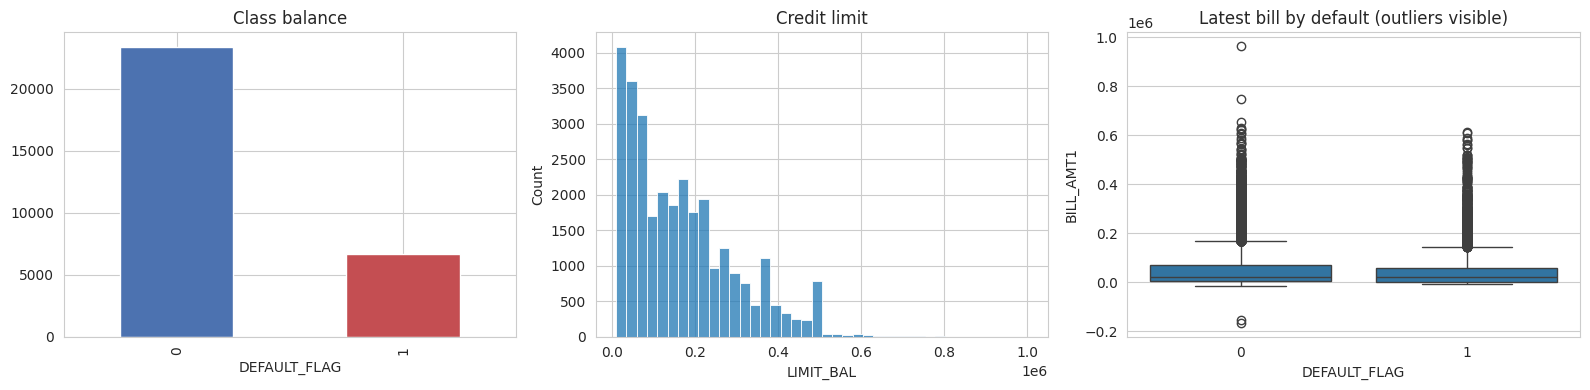

       LIMIT_BAL      AGE  BILL_AMT1  PAY_AMT1
count    30000.0  30000.0    30000.0   30000.0
mean    167484.0     35.0    51223.0    5664.0
std     129748.0      9.0    73636.0   16563.0
min      10000.0     21.0  -165580.0       0.0
25%      50000.0     28.0     3559.0    1000.0
50%     140000.0     34.0    22382.0    2100.0
75%     240000.0     41.0    67091.0    5006.0
max    1000000.0     79.0   964511.0  873552.0


In [39]:
import matplotlib.pyplot as plt, seaborn as sns
sns.set_style("whitegrid")
print(df.DEFAULT_FLAG.value_counts(normalize=True).round(3))
print("Majority-class accuracy:", round(1 - df.DEFAULT_FLAG.mean(), 3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df.DEFAULT_FLAG.value_counts().plot.bar(ax=ax[0], color=["#4C72B0", "#C44E52"], title="Class balance")
sns.histplot(df.LIMIT_BAL, bins=40, ax=ax[1]).set_title("Credit limit")
sns.boxplot(data=df, x="DEFAULT_FLAG", y="BILL_AMT1", ax=ax[2]).set_title("Latest bill by default (outliers visible)")
plt.tight_layout(); plt.savefig("reports/figures/eda_overview.png", dpi=150); plt.show()

print(df[["LIMIT_BAL","AGE","BILL_AMT1","PAY_AMT1"]].describe().round(0))

chi-square (categorical) and Mann-Whitney (numeric)

In [40]:
from scipy.stats import chi2_contingency, mannwhitneyu

rows = []
for c in ["SEX", "EDUCATION", "MARRIAGE", "PAY_1", "PAY_2", "PAY_3"]:
    ct = pd.crosstab(df[c], df.DEFAULT_FLAG)
    chi2, p, dof, _ = chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))     # Cramér's V = effect size
    rows.append([c, "chi-square", p, v])

for c in ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1", "PAY_AMT2"]:
    a, b = df.loc[df.DEFAULT_FLAG == 1, c], df.loc[df.DEFAULT_FLAG == 0, c]
    u, p = mannwhitneyu(a, b)
    rbc = 1 - 2 * u / (len(a) * len(b))                             # rank-biserial effect size
    rows.append([c, "Mann-Whitney", p, abs(rbc)])

tests = pd.DataFrame(rows, columns=["feature", "test", "p_value", "effect_size"])
tests["significant_5pct"] = tests.p_value < 0.05
tests.to_csv("reports/stat_tests.csv", index=False)
display(tests.round(4))

,feature,test,p_value,effect_size,significant_5pct
0,SEX,chi-square,0.0000,0.0399,True
1,EDUCATION,chi-square,0.0000,0.0731,True
2,MARRIAGE,chi-square,0.0000,0.0306,True
3,PAY_1,chi-square,0.0000,0.4229,True
4,PAY_2,chi-square,0.0000,0.3403,True
5,PAY_3,chi-square,0.0000,0.2957,True
6,LIMIT_BAL,Mann-Whitney,0.0000,0.2356,True
7,AGE,Mann-Whitney,0.3725,0.0072,False
8,BILL_AMT1,Mann-Whitney,0.0000,0.0352,True
9,PAY_AMT1,Mann-Whitney,0.0000,0.2226,True


Step 4: Feature engineering

In [41]:
%%writefile src/features.py
import numpy as np, pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PAY  = [f"PAY_{i}" for i in range(1, 7)]
BILL = [f"BILL_AMT{i}" for i in range(1, 7)]
AMT  = [f"PAY_AMT{i}" for i in range(1, 7)]
CAT  = ["SEX", "EDUCATION", "MARRIAGE"]

def add_features(df):
    d = df.copy()
    for i in range(1, 7):
        d[f"UTIL_{i}"] = d[f"BILL_AMT{i}"] / d["LIMIT_BAL"]                 # credit utilization
    util = [f"UTIL_{i}" for i in range(1, 7)]
    d["UTIL_AVG"], d["UTIL_MAX"] = d[util].mean(axis=1), d[util].max(axis=1)

    bill_pos = d[BILL].clip(lower=0)
    for i in range(1, 7):                                                  # payment-to-bill ratio
        r = d[f"PAY_AMT{i}"] / bill_pos[f"BILL_AMT{i}"].replace(0, np.nan)
        d[f"PAYRATIO_{i}"] = r.clip(0, 1).fillna(1.0)                      # no bill -> nothing owed
    d["PAYRATIO_AVG"] = d[[f"PAYRATIO_{i}" for i in range(1, 7)]].mean(axis=1)
    tot = (d[AMT].sum(axis=1) / bill_pos.sum(axis=1).replace(0, np.nan)).clip(0, 1)
    d["PAYRATIO_TOTAL"] = tot.fillna(1.0)

    d["MAX_DELAY"]   = d[PAY].max(axis=1)                                   # worst delay
    d["LATE_MONTHS"] = (d[PAY] > 0).sum(axis=1)                             # months late
    d["REVOLVING_MONTHS"] = (d[PAY] == 0).sum(axis=1)
    d["BILL_TREND"]  = (d["BILL_AMT1"] - d["BILL_AMT6"]) / d["LIMIT_BAL"]   # debt growth vs limit
    return d.drop(columns=["ID"], errors="ignore")

def build_preprocess(X, scale):
    num = [c for c in X.columns if c not in CAT]
    return ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
         ("num", StandardScaler() if scale else "passthrough", num)],
        sparse_threshold=0)

Overwriting src/features.py


In [42]:
from features import add_features
full = add_features(df)
X, y = full.drop(columns="DEFAULT_FLAG"), full["DEFAULT_FLAG"]
print(X.shape)
new = ["UTIL_AVG","UTIL_MAX","PAYRATIO_AVG","PAYRATIO_TOTAL","MAX_DELAY","LATE_MONTHS","REVOLVING_MONTHS","BILL_TREND"]
print(full[new + ["DEFAULT_FLAG"]].corr()["DEFAULT_FLAG"].drop("DEFAULT_FLAG").round(3).sort_values())

(30000, 43)
REVOLVING_MONTHS   -0.153
PAYRATIO_TOTAL     -0.091
PAYRATIO_AVG       -0.083
BILL_TREND         -0.024
UTIL_MAX            0.082
UTIL_AVG            0.115
MAX_DELAY           0.331
LATE_MONTHS         0.398
Name: DEFAULT_FLAG, dtype: float64


Step 5: Modeling

In [43]:
print(X.isna().sum().sum(), np.isinf(X.select_dtypes("number")).sum().sum())

0 0


In [44]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline

from features import build_preprocess

SEED = 42
BEST_MODEL = "HistGradientBoosting"

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

models = {
    "Logistic Regression": Pipeline([
        ("prep", build_preprocess(X, scale=True)),
        ("clf", LogisticRegression(max_iter=2000, C=0.5)),
    ]),
    BEST_MODEL: Pipeline([
        ("prep", build_preprocess(X, scale=False)),
        ("clf", HistGradientBoostingClassifier(
            learning_rate=0.05,
            max_iter=400,
            max_leaf_nodes=15,
            l2_regularization=1.0,
            early_stopping=True,
            validation_fraction=0.1,
            random_state=SEED,
        )),
    ]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_records = []

for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring=["roc_auc", "average_precision"], n_jobs=-1,
    )
    cv_records.append([
        name,
        scores["test_roc_auc"].mean(), scores["test_roc_auc"].std(),
        scores["test_average_precision"].mean(), scores["test_average_precision"].std(),
    ])
    model.fit(X_train, y_train)

cv_results = pd.DataFrame(
    cv_records, columns=["model", "cv_roc_auc", "roc_auc_std", "cv_pr_auc", "pr_auc_std"]
).round(4)
cv_results.to_csv("reports/cv_results.csv", index=False)
cv_results

,model,cv_roc_auc,roc_auc_std,cv_pr_auc,pr_auc_std
0,Logistic Regression,0.7618,0.0071,0.5131,0.0142
1,HistGradientBoosting,0.7867,0.0037,0.5619,0.0067


Step 6: Evaluation

Majority-class accuracy: 0.779


,model,threshold,ROC_AUC,PR_AUC,KS,precision,recall,F1
0,Logistic Regression,0.50,0.746,0.505,0.391,0.641,0.295,0.404
1,Logistic Regression,best-F1 (0.26),0.746,0.505,0.391,0.480,0.564,0.519
2,HistGradientBoosting,0.50,0.781,0.556,0.428,0.666,0.364,0.471
3,HistGradientBoosting,best-F1 (0.25),0.781,0.556,0.428,0.496,0.601,0.544


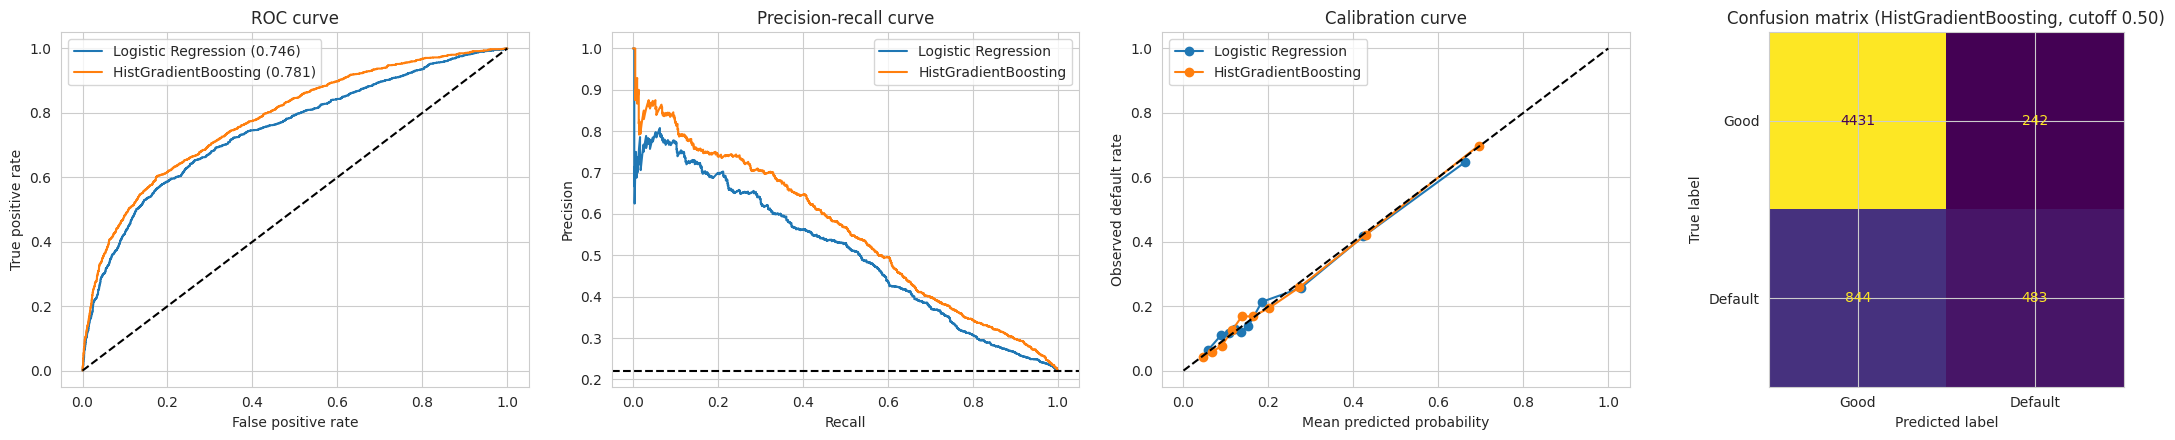

In [45]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, confusion_matrix, f1_score,
    precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,
)

scores = {name: model.predict_proba(X_test)[:, 1] for name, model in models.items()}
records = []

for name, prob in scores.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    precision, recall, thresholds = precision_recall_curve(y_test, prob)
    f1_curve = 2 * precision * recall / (precision + recall + 1e-9)
    f1_threshold = thresholds[np.argmax(f1_curve[:-1])]

    for label, cutoff in [("0.50", 0.5), (f"best-F1 ({f1_threshold:.2f})", f1_threshold)]:
        pred = (prob >= cutoff).astype(int)
        records.append([
            name, label,
            roc_auc_score(y_test, prob), average_precision_score(y_test, prob), (tpr - fpr).max(),
            precision_score(y_test, pred), recall_score(y_test, pred), f1_score(y_test, pred),
        ])

results = pd.DataFrame(
    records,
    columns=["model", "threshold", "ROC_AUC", "PR_AUC", "KS", "precision", "recall", "F1"],
).round(3)
results.to_csv("reports/test_results.csv", index=False)
print("Majority-class accuracy:", round(1 - y_test.mean(), 3))
display(results)

fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))

for name, prob in scores.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, prob):.3f})")
    precision, recall, _ = precision_recall_curve(y_test, prob)
    axes[1].plot(recall, precision, label=name)
    observed, predicted = calibration_curve(y_test, prob, n_bins=10, strategy="quantile")
    axes[2].plot(predicted, observed, "o-", label=name)

axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
axes[0].legend()

axes[1].axhline(y_test.mean(), ls="--", c="k")
axes[1].set(title="Precision-recall curve", xlabel="Recall", ylabel="Precision")
axes[1].legend()

axes[2].plot([0, 1], [0, 1], "k--")
axes[2].set(title="Calibration curve", xlabel="Mean predicted probability", ylabel="Observed default rate")
axes[2].legend()

ConfusionMatrixDisplay(
    confusion_matrix(y_test, scores[BEST_MODEL] >= 0.5),
    display_labels=["Good", "Default"],
).plot(ax=axes[3], colorbar=False)
axes[3].set_title(f"Confusion matrix ({BEST_MODEL}, cutoff 0.50)")

plt.tight_layout()
plt.savefig("reports/figures/evaluation.png", dpi=150)
plt.show()

Step 7: Business decision layer

Theoretical cutoff under calibration: 0.167
Optimal cutoff: 0.16 | approval rate 54.2% | bad rate among approved 9.9%
Cost: approve-all 6,635 | reject-all 4,673 | model 3,344
Saving vs approve-all: 49.6%
Saving vs best naive policy: 28.4%


,cutoff,approval_rate,bad_rate_among_approved,defaults_rejected,approved_defaults,rejected_good,total_cost
0,0.05,0.066,0.033,0.990,13,4293,4358
1,0.10,0.292,0.060,0.921,105,3026,3551
2,0.15,0.501,0.095,0.785,285,1949,3374
3,0.20,0.651,0.114,0.665,445,1211,3436
4,0.25,0.733,0.121,0.598,533,807,3472
5,0.30,0.773,0.130,0.547,601,635,3640
6,0.35,0.812,0.140,0.488,680,480,3880
7,0.40,0.846,0.149,0.429,758,355,4145
8,0.45,0.862,0.153,0.402,794,292,4262
9,0.50,0.879,0.160,0.364,844,242,4462


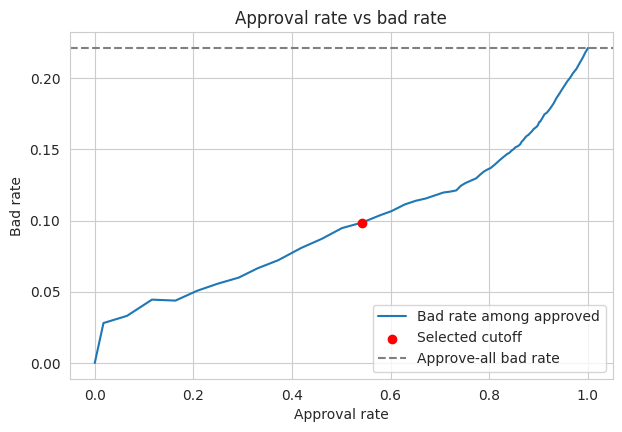

In [46]:
COST_FN = 5
COST_FP = 1

prob = scores[BEST_MODEL]
actual = y_test.values
n_defaults = int(actual.sum())
n_good = int((actual == 0).sum())


def evaluate_cutoff(cutoff):
    approved = prob < cutoff
    approved_defaults = int((approved & (actual == 1)).sum())
    rejected_good = int((~approved & (actual == 0)).sum())
    return {
        "cutoff": round(cutoff, 3),
        "approval_rate": approved.mean(),
        "bad_rate_among_approved": approved_defaults / max(approved.sum(), 1),
        "defaults_rejected": 1 - approved_defaults / n_defaults,
        "approved_defaults": approved_defaults,
        "rejected_good": rejected_good,
        "total_cost": COST_FN * approved_defaults + COST_FP * rejected_good,
    }


coarse_grid = pd.DataFrame([evaluate_cutoff(t) for t in np.arange(0.05, 0.85, 0.05)])
fine_grid = pd.DataFrame([evaluate_cutoff(t) for t in np.arange(0.02, 0.90, 0.01)])
optimum = fine_grid.loc[fine_grid["total_cost"].idxmin()]

approve_all_cost = COST_FN * n_defaults
reject_all_cost = COST_FP * n_good
naive_cost = min(approve_all_cost, reject_all_cost)

print(f"Theoretical cutoff under calibration: {COST_FP / (COST_FP + COST_FN):.3f}")
print(
    f"Optimal cutoff: {optimum['cutoff']} | approval rate {optimum['approval_rate']:.1%} "
    f"| bad rate among approved {optimum['bad_rate_among_approved']:.1%}"
)
print(f"Cost: approve-all {approve_all_cost:,} | reject-all {reject_all_cost:,} | model {optimum['total_cost']:,.0f}")
print(f"Saving vs approve-all: {1 - optimum['total_cost'] / approve_all_cost:.1%}")
print(f"Saving vs best naive policy: {1 - optimum['total_cost'] / naive_cost:.1%}")

coarse_grid.round(3).to_csv("reports/cutoff_table.csv", index=False)
display(coarse_grid.round(3))

plt.figure(figsize=(7, 4.5))
plt.plot(fine_grid["approval_rate"], fine_grid["bad_rate_among_approved"], label="Bad rate among approved")
plt.scatter(
    optimum["approval_rate"], optimum["bad_rate_among_approved"],
    c="red", zorder=5, label="Selected cutoff",
)
plt.axhline(actual.mean(), ls="--", c="grey", label="Approve-all bad rate")
plt.xlabel("Approval rate")
plt.ylabel("Bad rate")
plt.title("Approval rate vs bad rate")
plt.legend()
plt.savefig("reports/figures/approval_vs_badrate.png", dpi=150, bbox_inches="tight")
plt.show()

,customers,defaults,default_rate,avg_score,lift,cumulative_capture
decile,,,,,,
1,600,419,0.698,0.695,3.157,0.316
2,600,253,0.422,0.429,1.907,0.506
3,600,155,0.258,0.273,1.168,0.623
4,600,116,0.193,0.201,0.874,0.711
5,600,101,0.168,0.163,0.761,0.787
6,600,101,0.168,0.137,0.761,0.863
7,600,75,0.125,0.115,0.565,0.919
8,600,46,0.077,0.090,0.347,0.954
9,600,35,0.058,0.067,0.264,0.980


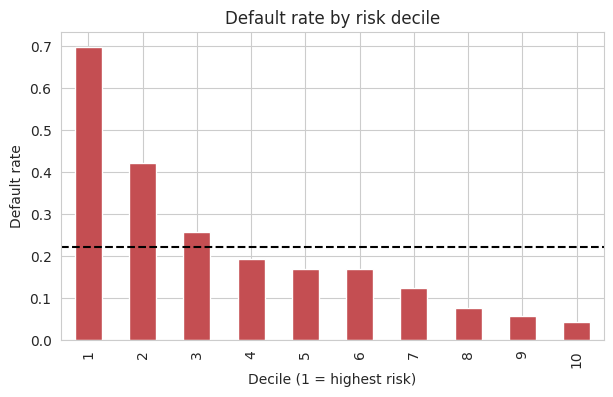

In [47]:
scored = pd.DataFrame({"y": actual, "score": prob})
scored["decile"] = pd.qcut(
    scored["score"].rank(method="first", ascending=False), 10, labels=range(1, 11)
)

lift = scored.groupby("decile", observed=True).agg(
    customers=("y", "size"),
    defaults=("y", "sum"),
    default_rate=("y", "mean"),
    avg_score=("score", "mean"),
)
lift["lift"] = lift["default_rate"] / scored["y"].mean()
lift["cumulative_capture"] = lift["defaults"].cumsum() / scored["y"].sum()
lift.round(3).to_csv("reports/decile_lift.csv")
display(lift.round(3))

ax = lift["default_rate"].plot.bar(figsize=(7, 4), color="#C44E52")
ax.axhline(scored["y"].mean(), ls="--", c="k")
ax.set(title="Default rate by risk decile", xlabel="Decile (1 = highest risk)", ylabel="Default rate")
plt.savefig("reports/figures/decile_lift.png", dpi=150, bbox_inches="tight")
plt.show()

Step 8: Explainability

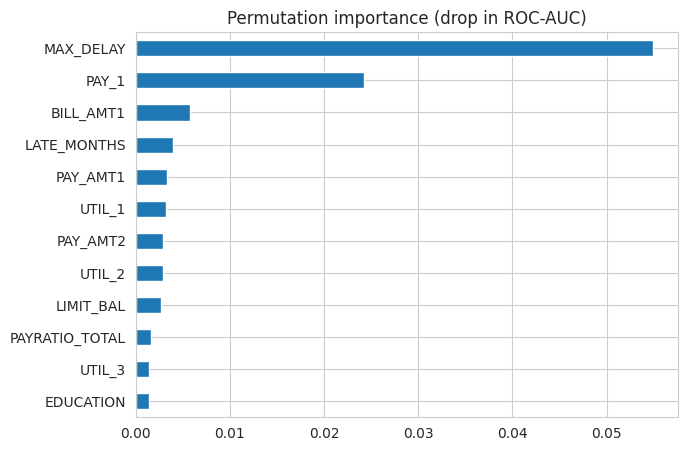

Predicted default probability: 0.832 | actual outcome: 1


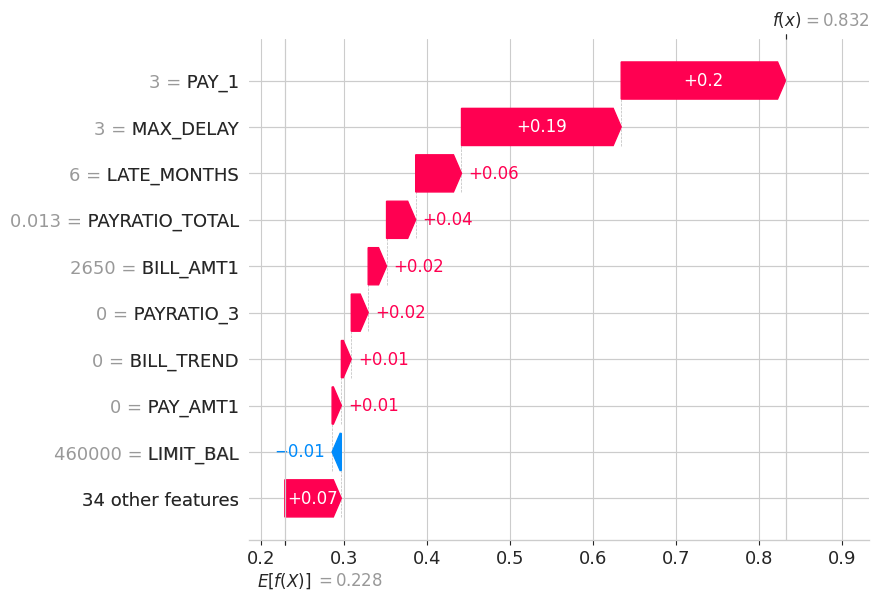

In [48]:
import shap
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    models[BEST_MODEL], X_test, y_test,
    scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1,
)
top_features = (
    pd.Series(importance.importances_mean, index=X.columns)
    .sort_values(ascending=False)
    .head(12)
)

top_features.iloc[::-1].plot.barh(figsize=(7, 5), title="Permutation importance (drop in ROC-AUC)")
plt.savefig("reports/figures/permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()

feature_names = list(X.columns)


def predict_default(data):
    return models[BEST_MODEL].predict_proba(pd.DataFrame(data, columns=feature_names))[:, 1]


background = X_train.sample(150, random_state=SEED)
explainer = shap.Explainer(predict_default, background, algorithm="permutation")

index = int(np.argmax(prob))
explanation = explainer(X_test.iloc[[index]], max_evals=1500)

print("Predicted default probability:", round(prob[index], 3), "| actual outcome:", actual[index])
shap.plots.waterfall(explanation[0], max_display=10, show=False)
plt.savefig("reports/figures/shap_one_prediction.png", dpi=150, bbox_inches="tight")
plt.show()

Step 9: Packaging

In [49]:
%%writefile requirements.txt
pandas>=2.0
numpy
scipy
scikit-learn>=1.4
matplotlib
seaborn
shap
xlrd
openpyxl
joblib

Overwriting requirements.txt


Step 1O: Monotonic-constrained model

In [50]:
import joblib
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from sklearn.model_selection import cross_validate

MONO_MODEL = "HGB Monotonic"

MONOTONIC_CONSTRAINTS = {
    "MAX_DELAY": 1,
    "LATE_MONTHS": 1,
    "UTIL_AVG": 1,
    "PAYRATIO_AVG": -1,
    "PAYRATIO_TOTAL": -1,
}

mono_preprocessor = (
    build_preprocess(X, scale=False)
    .set_params(verbose_feature_names_out=False)
    .set_output(transform="pandas")
)

models[MONO_MODEL] = Pipeline([
    ("prep", mono_preprocessor),
    ("clf", HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=400,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        early_stopping=True,
        validation_fraction=0.1,
        monotonic_cst=MONOTONIC_CONSTRAINTS,
        random_state=SEED,
    )),
])

cv_scores = cross_validate(
    models[MONO_MODEL], X_train, y_train, cv=cv,
    scoring=["roc_auc", "average_precision"], n_jobs=-1,
)
models[MONO_MODEL].fit(X_train, y_train)
scores[MONO_MODEL] = models[MONO_MODEL].predict_proba(X_test)[:, 1]

comparison = []
for name in ["Logistic Regression", BEST_MODEL, MONO_MODEL]:
    fpr, tpr, _ = roc_curve(y_test, scores[name])
    comparison.append([
        name,
        roc_auc_score(y_test, scores[name]),
        average_precision_score(y_test, scores[name]),
        (tpr - fpr).max(),
    ])

comparison = pd.DataFrame(comparison, columns=["model", "ROC_AUC", "PR_AUC", "KS"]).round(4)
comparison.to_csv("reports/monotonic_comparison.csv", index=False)
print("Monotonic model CV ROC-AUC: {:.4f} +/- {:.4f}".format(
    cv_scores["test_roc_auc"].mean(), cv_scores["test_roc_auc"].std()))
display(comparison)

joblib.dump(models[MONO_MODEL], "models/hgb_monotonic.joblib")

Monotonic model CV ROC-AUC: 0.7870 +/- 0.0035


,model,ROC_AUC,PR_AUC,KS
0,Logistic Regression,0.7463,0.5055,0.3912
1,HistGradientBoosting,0.7812,0.5556,0.4282
2,HGB Monotonic,0.7804,0.5573,0.4294


['models/hgb_monotonic.joblib']

Step 11: Prove the constraints hold

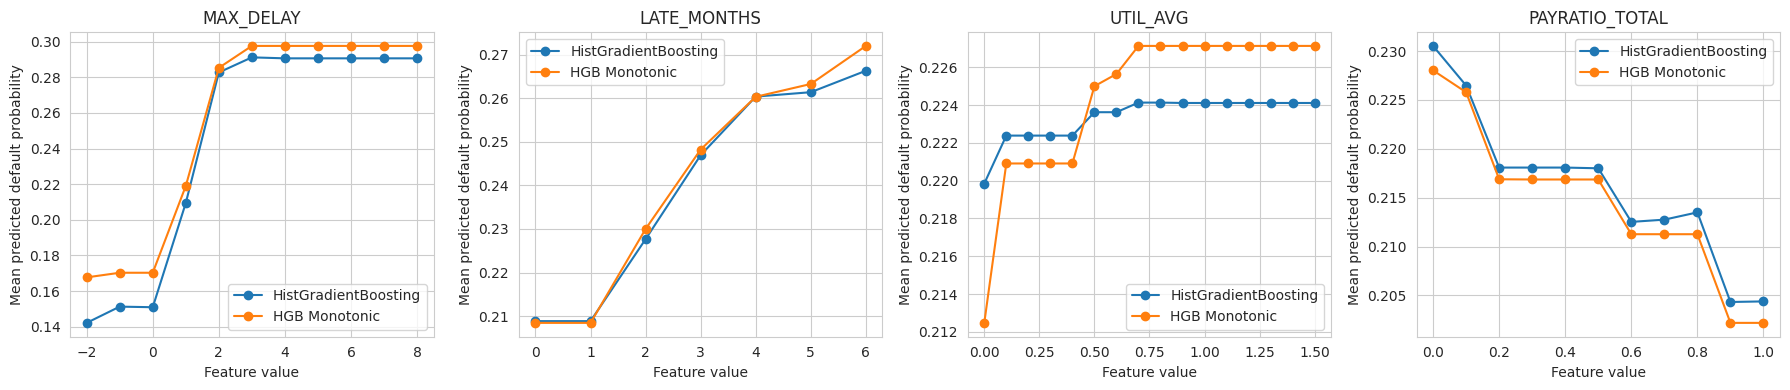

,feature,model,monotonicity_violations
0,MAX_DELAY,HistGradientBoosting,2
1,MAX_DELAY,HGB Monotonic,0
2,LATE_MONTHS,HistGradientBoosting,0
3,LATE_MONTHS,HGB Monotonic,0
4,UTIL_AVG,HistGradientBoosting,1
5,UTIL_AVG,HGB Monotonic,0
6,PAYRATIO_TOTAL,HistGradientBoosting,3
7,PAYRATIO_TOTAL,HGB Monotonic,0


In [51]:
sample = X_test.sample(1000, random_state=SEED)

sweeps = {
    "MAX_DELAY": (np.arange(-2, 9), 1),
    "LATE_MONTHS": (np.arange(0, 7), 1),
    "UTIL_AVG": (np.linspace(0, 1.5, 16), 1),
    "PAYRATIO_TOTAL": (np.linspace(0, 1, 11), -1),
}


def sweep_response(model, feature, grid):
    means = []
    for value in grid:
        frame = sample.copy()
        frame[feature] = value
        means.append(model.predict_proba(frame)[:, 1].mean())
    return np.array(means)


def count_violations(curve, direction):
    steps = np.diff(curve) * direction
    return int((steps < -1e-9).sum())


fig, axes = plt.subplots(1, len(sweeps), figsize=(18, 4))
audit = []

for ax, (feature, (grid, direction)) in zip(axes, sweeps.items()):
    for name in [BEST_MODEL, MONO_MODEL]:
        curve = sweep_response(models[name], feature, grid)
        audit.append([feature, name, count_violations(curve, direction)])
        ax.plot(grid, curve, marker="o", label=name)
    ax.set(title=feature, xlabel="Feature value", ylabel="Mean predicted default probability")
    ax.legend()

plt.tight_layout()
plt.savefig("reports/figures/monotonic_check.png", dpi=150)
plt.show()

violations = pd.DataFrame(audit, columns=["feature", "model", "monotonicity_violations"])
violations.to_csv("reports/monotonic_violations.csv", index=False)
violations

Step 12: Out-of-fold predictions and cost-ratio sensitivity

Calibration check | out-of-fold: predicted 0.221 vs observed 0.221 | test: predicted 0.221 vs observed 0.221


,cost_ratio,theoretical_cutoff,chosen_cutoff,approval_rate,bad_rate_among_approved,defaults_rejected,saving_vs_approve_all,saving_vs_best_naive
0,1,0.500,0.51,0.882,0.161,0.359,0.186,0.186
1,2,0.333,0.31,0.782,0.132,0.532,0.306,0.306
2,3,0.250,0.25,0.732,0.121,0.599,0.396,0.396
3,5,0.167,0.16,0.534,0.097,0.767,0.499,0.288
4,7,0.125,0.13,0.412,0.081,0.849,0.591,0.187
5,10,0.091,0.09,0.252,0.057,0.934,0.690,0.119
6,15,0.062,0.06,0.130,0.040,0.977,0.780,0.061
7,20,0.048,0.06,0.130,0.040,0.977,0.829,0.028


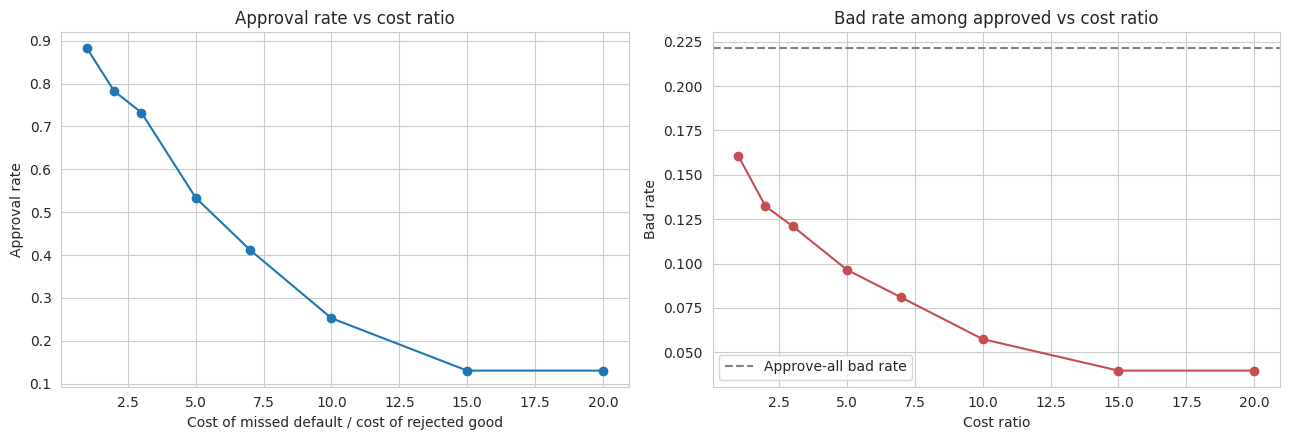

In [52]:
from sklearn.model_selection import cross_val_predict

FINAL_MODEL = MONO_MODEL
CUTOFFS = np.round(np.arange(0.02, 0.90, 0.01), 2)
RATIOS = [1, 2, 3, 5, 7, 10, 15, 20]

oof_prob = cross_val_predict(
    models[FINAL_MODEL], X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]
test_prob = scores[FINAL_MODEL]
train_actual = y_train.values
test_actual = y_test.values

print(
    f"Calibration check | out-of-fold: predicted {oof_prob.mean():.3f} vs observed {train_actual.mean():.3f}"
    f" | test: predicted {test_prob.mean():.3f} vs observed {test_actual.mean():.3f}"
)


def policy_cost(prob, actual, cutoff, ratio):
    approved = prob < cutoff
    missed_defaults = np.sum(approved & (actual == 1))
    rejected_good = np.sum(~approved & (actual == 0))
    return ratio * missed_defaults + rejected_good


sensitivity = []
cutoff_by_ratio = {}

for ratio in RATIOS:
    train_costs = [policy_cost(oof_prob, train_actual, c, ratio) for c in CUTOFFS]
    chosen = float(CUTOFFS[int(np.argmin(train_costs))])
    cutoff_by_ratio[ratio] = chosen

    approved = test_prob < chosen
    cost = policy_cost(test_prob, test_actual, chosen, ratio)
    approve_all = ratio * test_actual.sum()
    reject_all = (test_actual == 0).sum()
    naive = min(approve_all, reject_all)

    sensitivity.append({
        "cost_ratio": ratio,
        "theoretical_cutoff": round(1 / (1 + ratio), 3),
        "chosen_cutoff": chosen,
        "approval_rate": approved.mean(),
        "bad_rate_among_approved": test_actual[approved].mean(),
        "defaults_rejected": 1 - test_actual[approved].sum() / test_actual.sum(),
        "saving_vs_approve_all": 1 - cost / approve_all,
        "saving_vs_best_naive": 1 - cost / naive,
    })

sensitivity = pd.DataFrame(sensitivity)
sensitivity.round(3).to_csv("reports/cost_sensitivity.csv", index=False)
display(sensitivity.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(sensitivity["cost_ratio"], sensitivity["approval_rate"], marker="o")
axes[0].set(
    title="Approval rate vs cost ratio",
    xlabel="Cost of missed default / cost of rejected good",
    ylabel="Approval rate",
)
axes[1].plot(sensitivity["cost_ratio"], sensitivity["bad_rate_among_approved"], marker="o", color="#C44E52")
axes[1].axhline(test_actual.mean(), ls="--", c="grey", label="Approve-all bad rate")
axes[1].set(title="Bad rate among approved vs cost ratio", xlabel="Cost ratio", ylabel="Bad rate")
axes[1].legend()
plt.tight_layout()
plt.savefig("reports/figures/cost_sensitivity.png", dpi=150)
plt.show()

Step 13: Fairness Audit

Policy: cost ratio 5x, cutoff 0.16


,attribute,group,n,default_rate,approval_rate,bad_rate_among_approved,false_positive_rate,true_positive_rate,small_sample,disparate_impact,fails_four_fifths
0,sex,Female,3598,0.213,0.566,0.097,0.351,0.743,False,1.000,False
1,sex,Male,2402,0.234,0.486,0.096,0.427,0.800,False,0.859,False
2,education,Graduate school,2130,0.190,0.610,0.082,0.308,0.736,False,1.000,False
3,education,High school,1014,0.257,0.456,0.130,0.466,0.770,False,0.747,True
4,education,Other,82,0.061,0.902,0.027,0.065,0.600,True,1.479,False
5,education,University,2774,0.236,0.492,0.102,0.421,0.787,False,0.807,False
6,age,<25,541,0.253,0.403,0.101,0.515,0.839,False,0.695,True
7,age,25-34,2518,0.201,0.579,0.088,0.339,0.746,False,1.000,False
8,age,35-44,1855,0.225,0.540,0.103,0.376,0.753,False,0.931,False
9,age,45-54,859,0.247,0.482,0.109,0.430,0.788,False,0.832,False


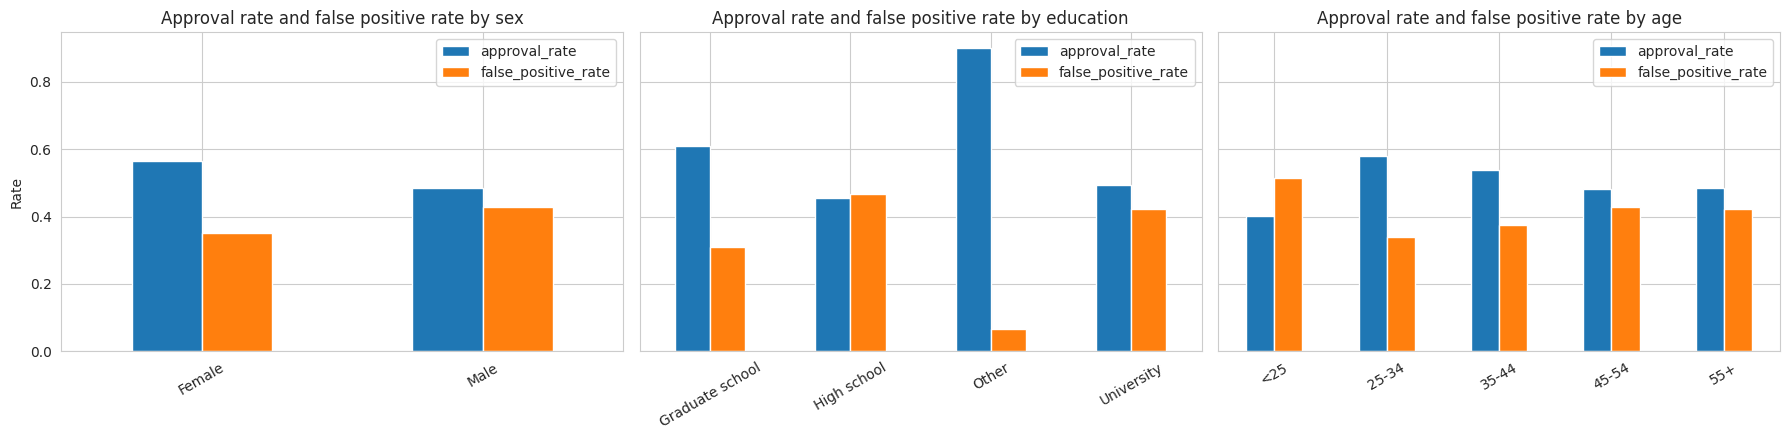

In [53]:
POLICY_RATIO = 5
policy_cutoff = cutoff_by_ratio[POLICY_RATIO]

audit_frame = X_test[["SEX", "EDUCATION", "AGE"]].copy()
audit_frame["actual"] = test_actual
audit_frame["rejected"] = test_prob >= policy_cutoff

audit_frame["sex_group"] = audit_frame["SEX"].map({1: "Male", 2: "Female"})
audit_frame["education_group"] = audit_frame["EDUCATION"].map(
    {1: "Graduate school", 2: "University", 3: "High school", 4: "Other"}
)
audit_frame["age_group"] = pd.cut(
    audit_frame["AGE"], bins=[0, 24, 34, 44, 54, 120],
    labels=["<25", "25-34", "35-44", "45-54", "55+"],
)


def audit_attribute(frame, column):
    rows = []
    for group, part in frame.groupby(column, observed=True):
        approved = ~part["rejected"]
        goods = part["actual"] == 0
        defaults = part["actual"] == 1
        rows.append({
            "attribute": column.replace("_group", ""),
            "group": group,
            "n": len(part),
            "default_rate": part["actual"].mean(),
            "approval_rate": approved.mean(),
            "bad_rate_among_approved": part.loc[approved, "actual"].mean(),
            "false_positive_rate": part.loc[goods, "rejected"].mean(),
            "true_positive_rate": part.loc[defaults, "rejected"].mean(),
        })
    result = pd.DataFrame(rows)
    result["small_sample"] = result["n"] < 100
    reference = result.loc[~result["small_sample"], "approval_rate"].max()
    result["disparate_impact"] = result["approval_rate"] / reference
    result["fails_four_fifths"] = (result["disparate_impact"] < 0.8) & ~result["small_sample"]
    return result


fairness = pd.concat(
    [audit_attribute(audit_frame, c) for c in ["sex_group", "education_group", "age_group"]],
    ignore_index=True,
)
fairness.round(3).to_csv("reports/fairness_audit.csv", index=False)
print(f"Policy: cost ratio {POLICY_RATIO}x, cutoff {policy_cutoff}")
display(fairness.round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, attribute in zip(axes, ["sex", "education", "age"]):
    part = fairness[fairness["attribute"] == attribute].set_index("group")
    part[["approval_rate", "false_positive_rate"]].plot.bar(ax=ax, rot=30)
    ax.set_title(f"Approval rate and false positive rate by {attribute}")
    ax.set_xlabel("")
axes[0].set_ylabel("Rate")
plt.tight_layout()
plt.savefig("reports/figures/fairness_audit.png", dpi=150)
plt.show()

Step 14: Updated run_pipeline.py (New Productivity Check)

In [54]:
%%writefile src/run_pipeline.py
import json
import os
import sys

import joblib
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline

sys.path.append(os.path.dirname(__file__))

from data import TARGET, load_clean
from features import add_features, build_preprocess

SEED = 42
POLICY_RATIO = 5
RATIOS = [1, 2, 3, 5, 7, 10, 15, 20]
CUTOFFS = np.round(np.arange(0.02, 0.90, 0.01), 2)
MONOTONIC_CONSTRAINTS = {
    "MAX_DELAY": 1,
    "LATE_MONTHS": 1,
    "UTIL_AVG": 1,
    "PAYRATIO_AVG": -1,
    "PAYRATIO_TOTAL": -1,
}


def build_model(X):
    preprocessor = (
        build_preprocess(X, scale=False)
        .set_params(verbose_feature_names_out=False)
        .set_output(transform="pandas")
    )
    return Pipeline([
        ("prep", preprocessor),
        ("clf", HistGradientBoostingClassifier(
            learning_rate=0.05,
            max_iter=400,
            max_leaf_nodes=15,
            l2_regularization=1.0,
            early_stopping=True,
            validation_fraction=0.1,
            monotonic_cst=MONOTONIC_CONSTRAINTS,
            random_state=SEED,
        )),
    ])


def policy_cost(prob, actual, cutoff, ratio):
    approved = prob < cutoff
    missed_defaults = np.sum(approved & (actual == 1))
    rejected_good = np.sum(~approved & (actual == 0))
    return ratio * missed_defaults + rejected_good


def select_cutoff(prob, actual, ratio):
    costs = [policy_cost(prob, actual, c, ratio) for c in CUTOFFS]
    return float(CUTOFFS[int(np.argmin(costs))])


def evaluate_policy(prob, actual, cutoff, ratio):
    approved = prob < cutoff
    cost = policy_cost(prob, actual, cutoff, ratio)
    approve_all = ratio * actual.sum()
    reject_all = (actual == 0).sum()
    return {
        "cost_ratio": ratio,
        "theoretical_cutoff": round(1 / (1 + ratio), 3),
        "chosen_cutoff": cutoff,
        "approval_rate": float(approved.mean()),
        "bad_rate_among_approved": float(actual[approved].mean()),
        "defaults_rejected": float(1 - actual[approved].sum() / actual.sum()),
        "saving_vs_approve_all": float(1 - cost / approve_all),
        "saving_vs_best_naive": float(1 - cost / min(approve_all, reject_all)),
    }


def main():
    os.makedirs("reports", exist_ok=True)
    os.makedirs("models", exist_ok=True)

    full = add_features(load_clean())
    X, y = full.drop(columns=TARGET), full[TARGET]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=SEED
    )

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    oof_prob = cross_val_predict(
        build_model(X), X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
    )[:, 1]

    model = build_model(X).fit(X_train, y_train)
    test_prob = model.predict_proba(X_test)[:, 1]
    train_actual, test_actual = y_train.values, y_test.values

    rows = [
        evaluate_policy(test_prob, test_actual, select_cutoff(oof_prob, train_actual, r), r)
        for r in RATIOS
    ]
    sensitivity = pd.DataFrame(rows)
    sensitivity.to_csv("reports/pipeline_cost_sensitivity.csv", index=False)
    policy = sensitivity.loc[sensitivity["cost_ratio"] == POLICY_RATIO].iloc[0]

    fpr, tpr, _ = roc_curve(test_actual, test_prob)
    metrics = {
        "model": "HistGradientBoosting (monotonic)",
        "roc_auc": float(roc_auc_score(test_actual, test_prob)),
        "pr_auc": float(average_precision_score(test_actual, test_prob)),
        "ks": float((tpr - fpr).max()),
        "policy_cost_ratio": POLICY_RATIO,
        "cutoff": float(policy["chosen_cutoff"]),
        "approval_rate": float(policy["approval_rate"]),
        "bad_rate_among_approved": float(policy["bad_rate_among_approved"]),
        "saving_vs_approve_all": float(policy["saving_vs_approve_all"]),
        "saving_vs_best_naive": float(policy["saving_vs_best_naive"]),
    }

    with open("reports/metrics.json", "w") as handle:
        json.dump(metrics, handle, indent=2)
    joblib.dump(model, "models/hgb_monotonic.joblib")
    print(json.dumps(metrics, indent=2))


if __name__ == "__main__":
    main()

Overwriting src/run_pipeline.py


In [55]:
!python src/run_pipeline.py

{
  "model": "HistGradientBoosting (monotonic)",
  "roc_auc": 0.7803961605987094,
  "pr_auc": 0.5572958324368267,
  "ks": 0.429397437958701,
  "policy_cost_ratio": 5,
  "cutoff": 0.16,
  "approval_rate": 0.5336666666666666,
  "bad_rate_among_approved": 0.09650218613366646,
  "saving_vs_approve_all": 0.49886963074604374,
  "saving_vs_best_naive": 0.2884656537556174
}


In [56]:
!rm -f reports/cutoff_table_full.csv models/hgb_pipeline.joblib
!ls reports models

models:
hgb_monotonic.joblib

reports:
bootstrap_four_fifths_probability.csv	expected_profit_limit_bands.csv
bootstrap_paired_differences.csv	expected_profit_policies.csv
bootstrap_summary.csv			expected_profit_robustness.csv
cost_sensitivity.csv			expected_profit_spike_profile.csv
cutoff_table.csv			fairness_audit.csv
cv_results.csv				figures
decile_lift.csv				metrics.json
demographics_ablation_fairness.csv	monotonic_comparison.csv
demographics_ablation_performance.csv	monotonic_violations.csv
expected_profit_disparate_impact.csv	pipeline_cost_sensitivity.csv
expected_profit_fairness_bootstrap.csv	stat_tests.csv
expected_profit_floor_sensitivity.csv	test_results.csv


Step 13b: does removing demographics fix the age and education flags?

,variant,features,ROC_AUC,PR_AUC,KS,cutoff,approval_rate,bad_rate_among_approved,saving_vs_best_naive
0,Full (monotonic),43,0.7804,0.5573,0.4294,0.16,0.5337,0.0965,0.2885
1,"Drop SEX, MARRIAGE, AGE",40,0.7798,0.5549,0.4258,0.16,0.5320,0.0993,0.2761
2,Drop all demographics,39,0.7783,0.5520,0.4315,0.16,0.5338,0.0993,0.2771


Disparate impact (below 0.80 fails the screen)


variant                    Full (monotonic)  Drop SEX, MARRIAGE, AGE  \
attribute group                                                        
age       25-34                       1.000                    1.000   
          35-44                       0.931                    0.972   
          45-54                       0.832                    0.908   
          55+                         0.836                    0.930   
          <25                         0.695                    0.642   
education Graduate school             1.000                    1.000   
          High school                 0.747                    0.757   
          University                  0.807                    0.795   
sex       Female                      1.000                    1.000   
          Male                        0.859                    0.925   

variant                    Drop all demographics  
attribute group                                   
age       25-34                            1.000  
          35-44                            0.977  
          45-54                            0.889  
          55+                              0.926  
          <25                              0.657  
education Graduate school                  1.000  
          High school                      0.765  
          University                       0.819  
sex       Female                           1.000  
          Male                             0.933

False positive rate (good customers wrongly rejected)


variant                    Full (monotonic)  Drop SEX, MARRIAGE, AGE  \
attribute group                                                        
age       25-34                       0.339                    0.358   
          35-44                       0.376                    0.366   
          45-54                       0.430                    0.396   
          55+                         0.422                    0.393   
          <25                         0.515                    0.562   
education Graduate school             0.308                    0.308   
          High school                 0.466                    0.456   
          University                  0.421                    0.433   
sex       Female                      0.351                    0.371   
          Male                        0.427                    0.405   

variant                    Drop all demographics  
attribute group                                   
age       25-34                            0.356  
          35-44                            0.362  
          45-54                            0.403  
          55+                              0.393  
          <25                              0.552  
education Graduate school                  0.312  
          High school                      0.454  
          University                       0.418  
sex       Female                           0.371  
          Male                             0.401

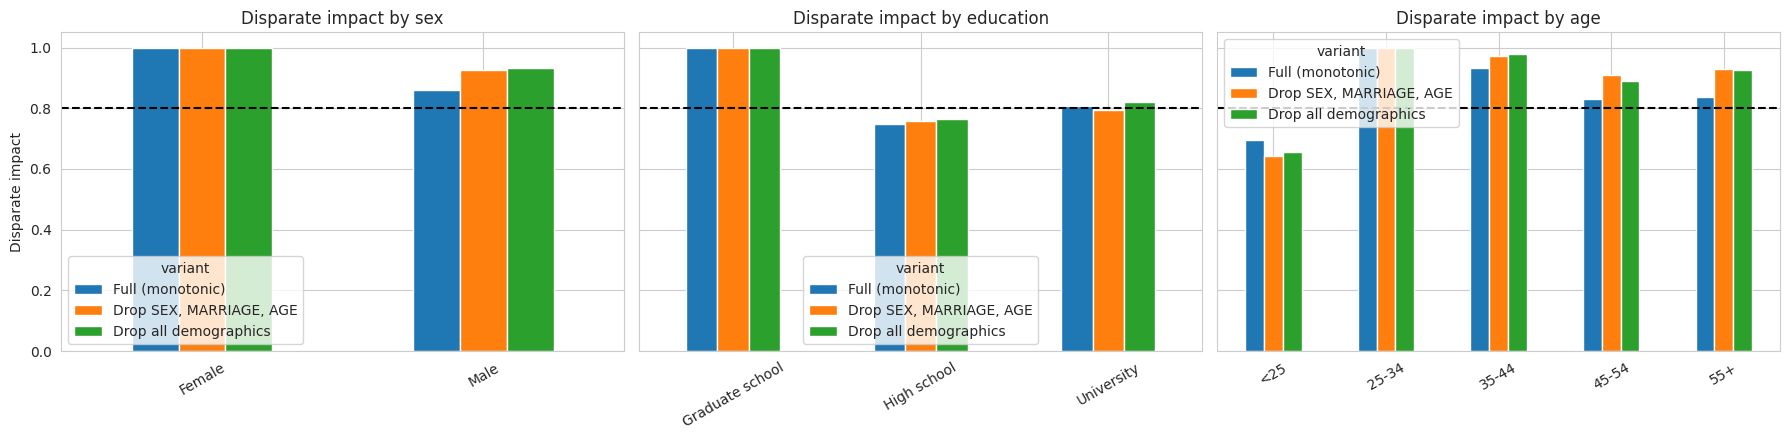

In [57]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

VARIANTS = {
    "Full (monotonic)": [],
    "Drop SEX, MARRIAGE, AGE": ["SEX", "MARRIAGE", "AGE"],
    "Drop all demographics": ["SEX", "MARRIAGE", "AGE", "EDUCATION"],
}
AUDIT_COLUMNS = ["sex_group", "education_group", "age_group"]


def build_reduced_model(columns):
    categorical = [c for c in ["EDUCATION"] if c in columns]
    numeric = [c for c in columns if c not in categorical]
    transformers = []
    if categorical:
        transformers.append(
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical)
        )
    transformers.append(("num", "passthrough", numeric))
    preprocessor = ColumnTransformer(
        transformers, sparse_threshold=0, verbose_feature_names_out=False
    ).set_output(transform="pandas")
    return Pipeline([
        ("prep", preprocessor),
        ("clf", HistGradientBoostingClassifier(
            learning_rate=0.05,
            max_iter=400,
            max_leaf_nodes=15,
            l2_regularization=1.0,
            early_stopping=True,
            validation_fraction=0.1,
            monotonic_cst=MONOTONIC_CONSTRAINTS,
            random_state=SEED,
        )),
    ])


performance = []
fairness_frames = []

for label, dropped in VARIANTS.items():
    columns = [c for c in X.columns if c not in dropped]

    if dropped:
        model = build_reduced_model(columns)
        variant_oof = cross_val_predict(
            model, X_train[columns], y_train, cv=cv, method="predict_proba", n_jobs=-1
        )[:, 1]
        model.fit(X_train[columns], y_train)
        variant_test = model.predict_proba(X_test[columns])[:, 1]
    else:
        variant_oof, variant_test = oof_prob, test_prob

    costs = [policy_cost(variant_oof, train_actual, c, POLICY_RATIO) for c in CUTOFFS]
    cutoff = float(CUTOFFS[int(np.argmin(costs))])

    approved = variant_test < cutoff
    cost = policy_cost(variant_test, test_actual, cutoff, POLICY_RATIO)
    naive = min(POLICY_RATIO * test_actual.sum(), (test_actual == 0).sum())
    fpr, tpr, _ = roc_curve(test_actual, variant_test)

    performance.append({
        "variant": label,
        "features": len(columns),
        "ROC_AUC": roc_auc_score(test_actual, variant_test),
        "PR_AUC": average_precision_score(test_actual, variant_test),
        "KS": (tpr - fpr).max(),
        "cutoff": cutoff,
        "approval_rate": approved.mean(),
        "bad_rate_among_approved": test_actual[approved].mean(),
        "saving_vs_best_naive": 1 - cost / naive,
    })

    variant_frame = audit_frame.copy()
    variant_frame["rejected"] = variant_test >= cutoff
    variant_fairness = pd.concat(
        [audit_attribute(variant_frame, c) for c in AUDIT_COLUMNS], ignore_index=True
    )
    variant_fairness["variant"] = label
    fairness_frames.append(variant_fairness)

performance = pd.DataFrame(performance)
performance.round(4).to_csv("reports/demographics_ablation_performance.csv", index=False)
display(performance.round(4))

fairness_all = pd.concat(fairness_frames, ignore_index=True)
fairness_all.round(3).to_csv("reports/demographics_ablation_fairness.csv", index=False)
reportable = fairness_all[~fairness_all["small_sample"]]
order = list(VARIANTS)

impact_table = reportable.pivot(
    index=["attribute", "group"], columns="variant", values="disparate_impact"
)[order]
fpr_table = reportable.pivot(
    index=["attribute", "group"], columns="variant", values="false_positive_rate"
)[order]
print("Disparate impact (below 0.80 fails the screen)")
display(impact_table.round(3))
print("False positive rate (good customers wrongly rejected)")
display(fpr_table.round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, attribute in zip(axes, ["sex", "education", "age"]):
    part = reportable[reportable["attribute"] == attribute].pivot(
        index="group", columns="variant", values="disparate_impact"
    )[order]
    groups = fairness_all.loc[fairness_all["attribute"] == attribute, "group"].drop_duplicates()
    part = part.reindex([g for g in groups if g in part.index])
    part.plot.bar(ax=ax, rot=30)
    ax.axhline(0.8, ls="--", c="k")
    ax.set_title(f"Disparate impact by {attribute}")
    ax.set_xlabel("")
axes[0].set_ylabel("Disparate impact")
plt.tight_layout()
plt.savefig("reports/figures/demographics_ablation.png", dpi=150)
plt.show()

Step 13c: To store each variant’s test predictions

In [58]:
BOOT_VARIANTS = {
    "Unconstrained": None,
    "Monotonic (full)": [],
    "Monotonic, drop SEX/MARRIAGE/AGE": ["SEX", "MARRIAGE", "AGE"],
    "Monotonic, drop all demographics": ["SEX", "MARRIAGE", "AGE", "EDUCATION"],
}
CUTOFF = cutoff_by_ratio[POLICY_RATIO]

variant_probs = {}
for label, dropped in BOOT_VARIANTS.items():
    if dropped is None:
        variant_probs[label] = scores[BEST_MODEL]
    elif not dropped:
        variant_probs[label] = test_prob
    else:
        columns = [c for c in X.columns if c not in dropped]
        reduced = build_reduced_model(columns).fit(X_train[columns], y_train)
        variant_probs[label] = reduced.predict_proba(X_test[columns])[:, 1]

earlier_23b = performance.set_index("variant")["ROC_AUC"]
earlier_20 = comparison.set_index("model")["ROC_AUC"]
reproduction = pd.DataFrame({
    "variant": list(variant_probs),
    "test_roc_auc": [roc_auc_score(test_actual, p) for p in variant_probs.values()],
    "earlier_value": [
        earlier_20[BEST_MODEL],
        earlier_23b["Full (monotonic)"],
        earlier_23b["Drop SEX, MARRIAGE, AGE"],
        earlier_23b["Drop all demographics"],
    ],
})
display(reproduction.round(4))
print("Policy cutoff applied to every variant:", CUTOFF)

,variant,test_roc_auc,earlier_value
0,Unconstrained,0.7812,0.7812
1,Monotonic (full),0.7804,0.7804
2,"Monotonic, drop SEX/MARRIAGE/AGE",0.7798,0.7798
3,"Monotonic, drop all demographics",0.7783,0.7783


Policy cutoff applied to every variant: 0.16


Step 13d: The Bootstrap Engine

In [59]:
N_BOOT = 1000
POINT = np.arange(len(test_actual))

sex_arr = audit_frame["sex_group"].astype(str).to_numpy()
edu_arr = audit_frame["education_group"].astype(str).to_numpy()
age_arr = audit_frame["age_group"].astype(str).to_numpy()


def group_rates(approved, y, groups, label):
    member = groups == label
    good = member & (y == 0)
    kept = member & approved
    return (
        approved[member].mean(),
        (~approved[good]).mean(),
        y[kept].mean() if kept.any() else np.nan,
    )


def evaluate(prob, idx):
    y = test_actual[idx]
    p = prob[idx]
    approved = p < CUTOFF
    fpr_curve, tpr_curve, _ = roc_curve(y, p)
    cost = POLICY_RATIO * np.sum(approved & (y == 1)) + np.sum(~approved & (y == 0))
    naive = min(POLICY_RATIO * y.sum(), (y == 0).sum())

    sex, edu, age = sex_arr[idx], edu_arr[idx], age_arr[idx]
    under25 = group_rates(approved, y, age, "<25")
    age_ref = group_rates(approved, y, age, "25-34")
    high_school = group_rates(approved, y, edu, "High school")
    university = group_rates(approved, y, edu, "University")
    graduate = group_rates(approved, y, edu, "Graduate school")
    male = group_rates(approved, y, sex, "Male")
    female = group_rates(approved, y, sex, "Female")

    return {
        "ROC_AUC": roc_auc_score(y, p),
        "KS": (tpr_curve - fpr_curve).max(),
        "approval_rate": approved.mean(),
        "bad_rate_among_approved": y[approved].mean(),
        "saving_vs_best_naive": 1 - cost / naive,
        "DI_under25": under25[0] / age_ref[0],
        "DI_high_school": high_school[0] / graduate[0],
        "DI_university": university[0] / graduate[0],
        "DI_male": male[0] / female[0],
        "FPR_gap_under25": under25[1] - age_ref[1],
        "FPR_gap_high_school": high_school[1] - graduate[1],
        "FPR_gap_male": male[1] - female[1],
        "BAD_gap_high_school": high_school[2] - graduate[2],
    }


rng = np.random.default_rng(SEED)
boot_idx = rng.integers(0, len(test_actual), size=(N_BOOT, len(test_actual)))

point_estimates = pd.DataFrame(
    {label: evaluate(prob, POINT) for label, prob in variant_probs.items()}
).T

boot = {
    label: pd.DataFrame([evaluate(prob, idx) for idx in boot_idx])
    for label, prob in variant_probs.items()
}

print({label: frame.shape for label, frame in boot.items()})
display(point_estimates.round(4))

{'Unconstrained': (1000, 13), 'Monotonic (full)': (1000, 13), 'Monotonic, drop SEX/MARRIAGE/AGE': (1000, 13), 'Monotonic, drop all demographics': (1000, 13)}


,ROC_AUC,KS,approval_rate,bad_rate_among_approved,saving_vs_best_naive,DI_under25,DI_high_school,DI_university,DI_male,FPR_gap_under25,FPR_gap_high_school,FPR_gap_male,BAD_gap_high_school
Unconstrained,0.7812,0.4282,0.5425,0.0986,0.2844,0.6880,0.7433,0.8139,0.8724,0.1812,0.1561,0.0662,0.0387
Monotonic (full),0.7804,0.4294,0.5337,0.0965,0.2885,0.6954,0.7465,0.8068,0.8590,0.1762,0.1577,0.0760,0.0476
"Monotonic, drop SEX/MARRIAGE/AGE",0.7798,0.4258,0.5320,0.0993,0.2761,0.6424,0.7572,0.7950,0.9255,0.2039,0.1471,0.0337,0.0428
"Monotonic, drop all demographics",0.7783,0.4315,0.5338,0.0993,0.2771,0.6565,0.7646,0.8195,0.9326,0.1959,0.1423,0.0301,0.0447


Step 13e: Intervals, Paired differences and Chart

Headline metrics: estimate [95% interval]


variant,Unconstrained,Monotonic (full),"Monotonic, drop SEX/MARRIAGE/AGE","Monotonic, drop all demographics"
metric,,,,
ROC_AUC,"0.781 [0.767, 0.796]","0.780 [0.766, 0.796]","0.780 [0.765, 0.795]","0.778 [0.764, 0.793]"
KS,"0.428 [0.402, 0.459]","0.429 [0.403, 0.459]","0.426 [0.400, 0.456]","0.432 [0.405, 0.463]"
approval_rate,"0.542 [0.529, 0.555]","0.534 [0.521, 0.546]","0.532 [0.519, 0.545]","0.534 [0.521, 0.546]"
bad_rate_among_approved,"0.099 [0.088, 0.109]","0.097 [0.086, 0.106]","0.099 [0.089, 0.109]","0.099 [0.088, 0.109]"
saving_vs_best_naive,"0.284 [0.243, 0.327]","0.288 [0.248, 0.329]","0.276 [0.237, 0.317]","0.277 [0.236, 0.319]"


Fairness metrics: estimate [95% interval]


variant,Unconstrained,Monotonic (full),"Monotonic, drop SEX/MARRIAGE/AGE","Monotonic, drop all demographics"
metric,,,,
DI_under25,"0.688 [0.615, 0.759]","0.695 [0.620, 0.764]","0.642 [0.565, 0.712]","0.657 [0.579, 0.729]"
DI_high_school,"0.743 [0.690, 0.798]","0.747 [0.695, 0.803]","0.757 [0.705, 0.814]","0.765 [0.710, 0.822]"
DI_university,"0.814 [0.774, 0.854]","0.807 [0.768, 0.846]","0.795 [0.755, 0.835]","0.819 [0.779, 0.860]"
DI_male,"0.872 [0.831, 0.914]","0.859 [0.819, 0.903]","0.925 [0.881, 0.971]","0.933 [0.890, 0.978]"
FPR_gap_under25,"0.181 [0.129, 0.234]","0.176 [0.125, 0.231]","0.204 [0.151, 0.258]","0.196 [0.147, 0.251]"
FPR_gap_high_school,"0.156 [0.116, 0.194]","0.158 [0.117, 0.198]","0.147 [0.104, 0.188]","0.142 [0.100, 0.183]"
FPR_gap_male,"0.066 [0.039, 0.094]","0.076 [0.048, 0.104]","0.034 [0.005, 0.063]","0.030 [0.002, 0.058]"
BAD_gap_high_school,"0.039 [0.006, 0.071]","0.048 [0.014, 0.081]","0.043 [0.010, 0.076]","0.045 [0.012, 0.079]"


Share of bootstrap replicates with disparate impact below 0.80


,Unconstrained,Monotonic (full),"Monotonic, drop SEX/MARRIAGE/AGE","Monotonic, drop all demographics"
DI_under25,0.997,0.998,1.000,1.000
DI_high_school,0.983,0.969,0.930,0.885
DI_university,0.230,0.381,0.592,0.176
DI_male,0.000,0.004,0.000,0.000


Paired differences between models


,comparison,metric,difference,ci_low,ci_high,excludes_zero
0,Monotonic (full) minus Unconstrained,ROC_AUC,-0.0008,-0.0027,0.0011,False
1,Monotonic (full) minus Unconstrained,KS,0.0012,-0.0080,0.0100,False
2,Monotonic (full) minus Unconstrained,saving_vs_best_naive,0.0041,-0.0119,0.0205,False
3,Monotonic (full) minus Unconstrained,DI_under25,0.0074,-0.0260,0.0397,False
4,Monotonic (full) minus Unconstrained,DI_male,-0.0134,-0.0322,0.0052,False
5,Monotonic (full) minus Unconstrained,FPR_gap_under25,-0.0050,-0.0269,0.0172,False
6,Monotonic (full) minus Unconstrained,FPR_gap_male,0.0097,-0.0025,0.0218,False
7,"Monotonic, drop SEX/MARRIAGE/AGE minus Monoton...",ROC_AUC,-0.0006,-0.0025,0.0014,False
8,"Monotonic, drop SEX/MARRIAGE/AGE minus Monoton...",KS,-0.0036,-0.0092,0.0047,False
9,"Monotonic, drop SEX/MARRIAGE/AGE minus Monoton...",saving_vs_best_naive,-0.0124,-0.0285,0.0030,False


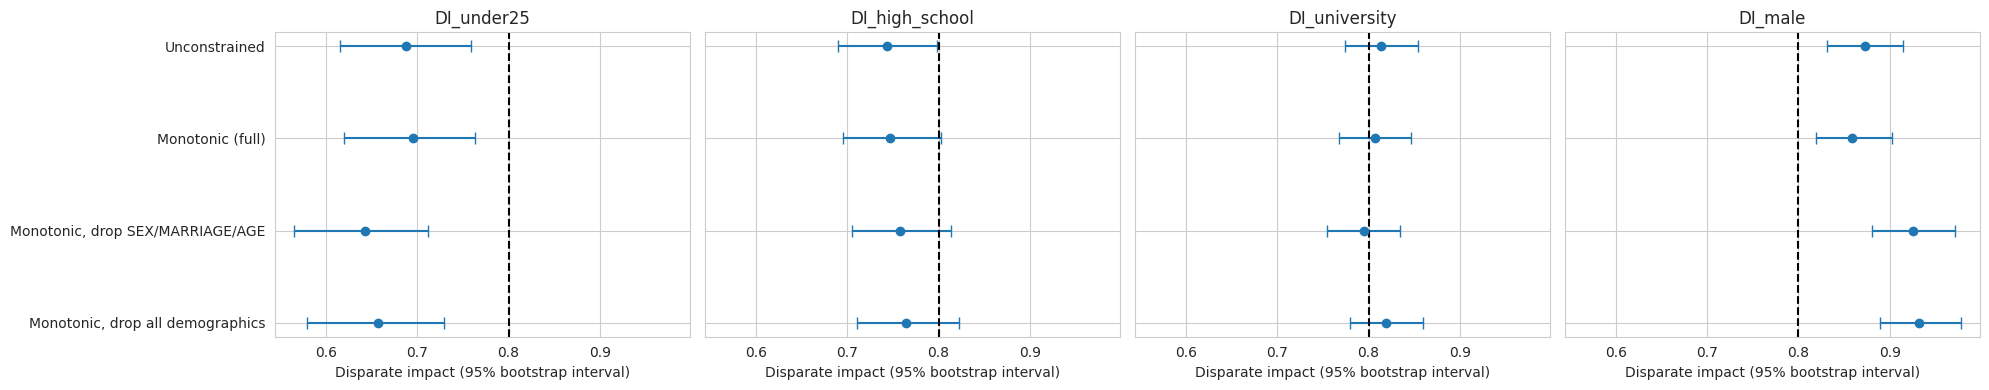

In [60]:
def interval(series):
    return series.quantile(0.025), series.quantile(0.975)


HEADLINE = ["ROC_AUC", "KS", "approval_rate", "bad_rate_among_approved", "saving_vs_best_naive"]
FAIRNESS = [
    "DI_under25", "DI_high_school", "DI_university", "DI_male",
    "FPR_gap_under25", "FPR_gap_high_school", "FPR_gap_male", "BAD_gap_high_school",
]
DI_METRICS = ["DI_under25", "DI_high_school", "DI_university", "DI_male"]
labels = list(variant_probs)

summary_rows = []
for label in labels:
    for metric in HEADLINE + FAIRNESS:
        low, high = interval(boot[label][metric])
        summary_rows.append({
            "variant": label,
            "metric": metric,
            "estimate": point_estimates.loc[label, metric],
            "ci_low": low,
            "ci_high": high,
        })

summary = pd.DataFrame(summary_rows)
summary.round(4).to_csv("reports/bootstrap_summary.csv", index=False)
summary["reported"] = summary.apply(
    lambda r: f"{r['estimate']:.3f} [{r['ci_low']:.3f}, {r['ci_high']:.3f}]", axis=1
)

print("Headline metrics: estimate [95% interval]")
display(
    summary[summary["metric"].isin(HEADLINE)]
    .pivot(index="metric", columns="variant", values="reported")
    .loc[HEADLINE][labels]
)
print("Fairness metrics: estimate [95% interval]")
display(
    summary[summary["metric"].isin(FAIRNESS)]
    .pivot(index="metric", columns="variant", values="reported")
    .loc[FAIRNESS][labels]
)

below_threshold = pd.DataFrame(
    {label: {m: (boot[label][m] < 0.8).mean() for m in DI_METRICS} for label in labels}
)
print("Share of bootstrap replicates with disparate impact below 0.80")
display(below_threshold.round(3))
below_threshold.round(3).to_csv("reports/bootstrap_four_fifths_probability.csv")

COMPARISONS = [
    ("Monotonic (full)", "Unconstrained"),
    ("Monotonic, drop SEX/MARRIAGE/AGE", "Monotonic (full)"),
    ("Monotonic, drop all demographics", "Monotonic (full)"),
]
DIFF_METRICS = [
    "ROC_AUC", "KS", "saving_vs_best_naive",
    "DI_under25", "DI_male", "FPR_gap_under25", "FPR_gap_male",
]

diff_rows = []
for a, b in COMPARISONS:
    for metric in DIFF_METRICS:
        delta = boot[a][metric] - boot[b][metric]
        low, high = interval(delta)
        diff_rows.append({
            "comparison": f"{a} minus {b}",
            "metric": metric,
            "difference": point_estimates.loc[a, metric] - point_estimates.loc[b, metric],
            "ci_low": low,
            "ci_high": high,
            "excludes_zero": bool(low > 0 or high < 0),
        })

paired = pd.DataFrame(diff_rows)
paired.round(4).to_csv("reports/bootstrap_paired_differences.csv", index=False)
print("Paired differences between models")
display(paired.round(4))

fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharex=True)
positions = np.arange(len(labels))
for ax, metric in zip(axes, DI_METRICS):
    part = summary[summary["metric"] == metric].set_index("variant").loc[labels]
    ax.errorbar(
        part["estimate"], positions,
        xerr=[part["estimate"] - part["ci_low"], part["ci_high"] - part["estimate"]],
        fmt="o", capsize=4,
    )
    ax.axvline(0.8, ls="--", c="k")
    ax.set_yticks(positions)
    ax.set_yticklabels(labels if metric == DI_METRICS[0] else [""] * len(labels))
    ax.invert_yaxis()
    ax.set_title(metric)
    ax.set_xlabel("Disparate impact (95% bootstrap interval)")
plt.tight_layout()
plt.savefig("reports/figures/bootstrap_fairness_ci.png", dpi=150)
plt.show()

Step 14: Exposure-aware expected-profit policy

Step 14a: Define the economics and compare policies

,policy,approval_rate,bad_rate_among_approved,total_profit,profit_per_applicant,profit_vs_flat
0,Approve all,1.0000,0.2212,3247.7603,0.5413,-0.4054
1,Reject all,0.0000,NaN,0.0000,0.0000,-1.0000
2,"Flat cutoff, tuned out-of-fold (0.23)",0.7055,0.1200,5461.6801,0.9103,0.0000
3,Exposure-aware expected profit,0.5285,0.1239,6839.6562,1.1399,0.2523


Distribution of customer-specific cutoffs


,0
count,6000.000
mean,0.238
std,0.172
min,0.001
5%,0.005
25%,0.046
50%,0.265
75%,0.401
95%,0.462
max,0.763


,flat,exposure_aware
band,,
100-200k,0.737,0.512
200-400k,0.814,0.457
400k+,0.908,0.540
50-100k,0.652,0.618
<50k,0.421,0.549


Disparate impact of each policy


,group,flat,exposure_aware
0,under 25,0.823,1.134
1,high school,0.870,1.192
2,university,0.895,1.190
3,male,0.955,1.091


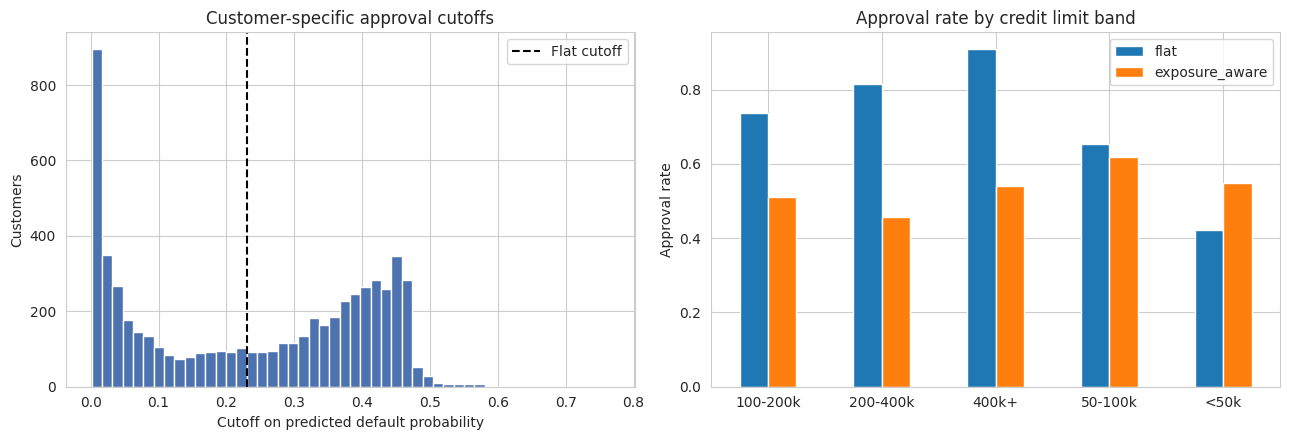

In [61]:
BILL_COLUMNS = [f"BILL_AMT{i}" for i in range(1, 7)]
BASE_CCF = 0.5
BASE_RATIO = 5.0


def raw_economics(frame, ccf):
    limit = frame["LIMIT_BAL"].to_numpy(dtype=float)
    drawn = np.clip(frame["BILL_AMT1"].to_numpy(dtype=float), 0, limit)
    exposure = drawn + ccf * (limit - drawn)
    revenue_base = frame[BILL_COLUMNS].clip(lower=0).mean(axis=1).to_numpy(dtype=float)
    return exposure, revenue_base


def fit_reference(frame, ccf):
    exposure, revenue_base = raw_economics(frame, ccf)
    floor = np.quantile(revenue_base[revenue_base > 0], 0.05)
    return {
        "floor": floor,
        "exposure_median": np.median(exposure),
        "margin_median": np.median(np.maximum(revenue_base, floor)),
    }


def customer_economics(frame, ccf, ratio, reference):
    exposure, revenue_base = raw_economics(frame, ccf)
    margin = np.maximum(revenue_base, reference["floor"]) / reference["margin_median"]
    loss = ratio * exposure / reference["exposure_median"]
    return margin, loss


def realized_profit(approved, outcome, margin, loss):
    return np.where(approved, np.where(outcome == 0, margin, -loss), 0.0)


def tuned_flat_cutoff(prob, outcome, margin, loss):
    totals = [realized_profit(prob < c, outcome, margin, loss).sum() for c in CUTOFFS]
    return float(CUTOFFS[int(np.argmax(totals))])


def run_scenario(ccf, ratio):
    reference = fit_reference(X_train, ccf)
    margin_train, loss_train = customer_economics(X_train, ccf, ratio, reference)
    margin_test, loss_test = customer_economics(X_test, ccf, ratio, reference)
    flat_cutoff = tuned_flat_cutoff(oof_prob, train_actual, margin_train, loss_train)
    customer_cutoff = margin_test / (margin_test + loss_test)
    return {
        "margin": margin_test,
        "loss": loss_test,
        "flat_cutoff": flat_cutoff,
        "customer_cutoff": customer_cutoff,
        "flat_approved": test_prob < flat_cutoff,
        "exposure_approved": test_prob < customer_cutoff,
    }


scenario = run_scenario(BASE_CCF, BASE_RATIO)
margin_test, loss_test = scenario["margin"], scenario["loss"]
flat_approved = scenario["flat_approved"]
exposure_approved = scenario["exposure_approved"]

policies = {
    "Approve all": np.ones(len(test_actual), dtype=bool),
    "Reject all": np.zeros(len(test_actual), dtype=bool),
    f"Flat cutoff, tuned out-of-fold ({scenario['flat_cutoff']:.2f})": flat_approved,
    "Exposure-aware expected profit": exposure_approved,
}

rows = []
for name, approved in policies.items():
    profit = realized_profit(approved, test_actual, margin_test, loss_test)
    rows.append({
        "policy": name,
        "approval_rate": approved.mean(),
        "bad_rate_among_approved": test_actual[approved].mean() if approved.any() else np.nan,
        "total_profit": profit.sum(),
        "profit_per_applicant": profit.mean(),
    })

policy_table = pd.DataFrame(rows)
policy_table["profit_vs_flat"] = policy_table["total_profit"] / policy_table["total_profit"].iloc[2] - 1
policy_table.round(4).to_csv("reports/expected_profit_policies.csv", index=False)
display(policy_table.round(4))

print("Distribution of customer-specific cutoffs")
display(pd.Series(scenario["customer_cutoff"]).describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(3))

bands = pd.cut(
    X_test["LIMIT_BAL"], bins=[0, 50000, 100000, 200000, 400000, np.inf],
    labels=["<50k", "50-100k", "100-200k", "200-400k", "400k+"], right=False,
)
band_table = (
    pd.DataFrame({"band": bands.to_numpy(), "flat": flat_approved, "exposure_aware": exposure_approved})
    .groupby("band", observed=True).mean()
)
display(band_table.round(3))

reference_groups = [
    ("under 25", age_arr, "<25", "25-34"),
    ("high school", edu_arr, "High school", "Graduate school"),
    ("university", edu_arr, "University", "Graduate school"),
    ("male", sex_arr, "Male", "Female"),
]
di_rows = []
for label, groups, target, reference_group in reference_groups:
    row = {"group": label}
    for policy_name, approved in [("flat", flat_approved), ("exposure_aware", exposure_approved)]:
        row[policy_name] = approved[groups == target].mean() / approved[groups == reference_group].mean()
    di_rows.append(row)
di_table = pd.DataFrame(di_rows)
di_table.round(3).to_csv("reports/expected_profit_disparate_impact.csv", index=False)
print("Disparate impact of each policy")
display(di_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(scenario["customer_cutoff"], bins=50, color="#4C72B0")
axes[0].axvline(scenario["flat_cutoff"], ls="--", c="k", label="Flat cutoff")
axes[0].set(title="Customer-specific approval cutoffs", xlabel="Cutoff on predicted default probability", ylabel="Customers")
axes[0].legend()
band_table.plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Approval rate by credit limit band", xlabel="", ylabel="Approval rate")
plt.tight_layout()
plt.savefig("reports/figures/expected_profit_policy.png", dpi=150)
plt.show()

Step 14b: Bootstrap and robustness grid

,ccf,ratio,flat_cutoff,flat_approval,exposure_approval,flat_profit_per_1000,exposure_profit_per_1000,uplift_per_1000,ci_low,ci_high,excludes_zero,uplift_pct
0,0.25,3.0,0.26,0.744,0.593,1097.937,1215.439,117.502,87.251,150.336,True,0.107
1,0.25,5.0,0.23,0.706,0.508,841.222,1009.439,168.217,128.010,210.524,True,0.200
2,0.25,7.0,0.18,0.595,0.451,630.129,815.209,185.080,132.516,235.768,True,0.294
3,0.25,10.0,0.13,0.412,0.366,442.306,574.566,132.260,32.583,229.385,True,0.299
4,0.50,3.0,0.26,0.744,0.601,1139.671,1307.047,167.376,136.159,201.542,True,0.147
5,0.50,5.0,0.23,0.706,0.528,910.280,1139.943,229.663,187.936,274.158,True,0.252
6,0.50,7.0,0.22,0.688,0.475,703.782,1003.568,299.786,247.849,358.671,True,0.426
7,0.50,10.0,0.18,0.595,0.418,451.875,802.185,350.310,276.880,423.077,True,0.775
8,0.75,3.0,0.26,0.744,0.602,1148.419,1342.847,194.428,159.996,228.409,True,0.169
9,0.75,5.0,0.23,0.706,0.533,925.486,1192.966,267.480,222.364,315.074,True,0.289


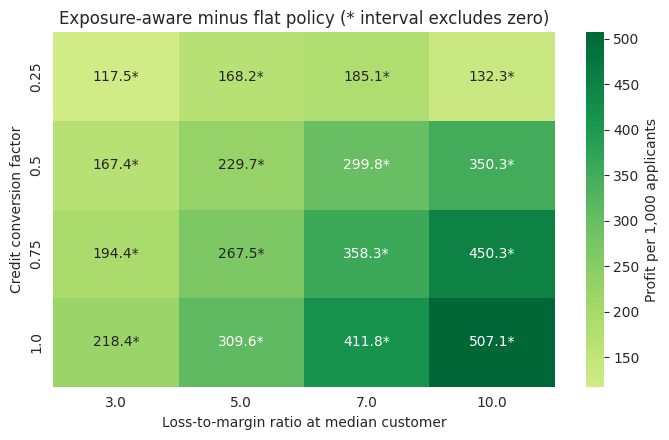

In [62]:
GRID_CCF = [0.25, 0.5, 0.75, 1.0]
GRID_RATIO = [3.0, 5.0, 7.0, 10.0]

grid_rows = []
for ccf in GRID_CCF:
    for ratio in GRID_RATIO:
        s = run_scenario(ccf, ratio)
        flat_profit = realized_profit(s["flat_approved"], test_actual, s["margin"], s["loss"])
        exposure_profit = realized_profit(s["exposure_approved"], test_actual, s["margin"], s["loss"])

        boot_difference = (exposure_profit[boot_idx] - flat_profit[boot_idx]).sum(axis=1) / len(test_actual) * 1000
        low, high = np.quantile(boot_difference, [0.025, 0.975])

        grid_rows.append({
            "ccf": ccf,
            "ratio": ratio,
            "flat_cutoff": s["flat_cutoff"],
            "flat_approval": s["flat_approved"].mean(),
            "exposure_approval": s["exposure_approved"].mean(),
            "flat_profit_per_1000": flat_profit.mean() * 1000,
            "exposure_profit_per_1000": exposure_profit.mean() * 1000,
            "uplift_per_1000": (exposure_profit.mean() - flat_profit.mean()) * 1000,
            "ci_low": low,
            "ci_high": high,
            "excludes_zero": bool(low > 0 or high < 0),
            "uplift_pct": exposure_profit.sum() / flat_profit.sum() - 1,
        })

grid = pd.DataFrame(grid_rows)
grid.round(4).to_csv("reports/expected_profit_robustness.csv", index=False)
display(grid.round(3))

uplift = grid.pivot(index="ccf", columns="ratio", values="uplift_per_1000")
significant = grid.pivot(index="ccf", columns="ratio", values="excludes_zero")
annotation = np.array([
    [f"{uplift.iloc[i, j]:.1f}{'*' if significant.iloc[i, j] else ''}" for j in range(uplift.shape[1])]
    for i in range(uplift.shape[0])
])

plt.figure(figsize=(7, 4.5))
sns.heatmap(uplift, annot=annotation, fmt="", cmap="RdYlGn", center=0, cbar_kws={"label": "Profit per 1,000 applicants"})
plt.title("Exposure-aware minus flat policy (* interval excludes zero)")
plt.xlabel("Loss-to-margin ratio at median customer")
plt.ylabel("Credit conversion factor")
plt.tight_layout()
plt.savefig("reports/figures/expected_profit_robustness.png", dpi=150)
plt.show()



Step 14c: Three cases

Margin-floor sensitivity (base case CCF 0.5, ratio 5)


,floor_quantile,flat_cutoff,flat_approval,exposure_approval,uplift_per_1000,ci_low,ci_high,excludes_zero,share_cutoff_under_2pct
0,0.05,0.23,0.706,0.528,229.663,187.936,274.158,True,0.164
1,0.10,0.23,0.706,0.528,228.472,186.833,272.948,True,0.148
2,0.25,0.23,0.706,0.544,206.575,164.723,251.074,True,0.002
3,0.50,0.26,0.744,0.706,93.743,55.292,133.782,True,0.000


Profile of customers with near-zero cutoffs


,customers,median_limit,median_avg_bill,median_exposure,mean_predicted_pd,default_rate,approval_rate,share_of_applicants
segment,,,,,,,,
cutoff 0.02 and above,5014,110000.0,29699.417,81387.25,0.220,0.212,0.632,0.836
cutoff under 0.02,986,220000.0,617.083,110000.00,0.226,0.268,0.000,0.164


Approval rate by credit limit band (ordered)


,flat,exposure_aware
band,,
<50k,0.421,0.549
50-100k,0.652,0.618
100-200k,0.737,0.512
200-400k,0.814,0.457
400k+,0.908,0.540


... (2 outputs left out)

Exposure-aware minus volume-matched flat: 281.6 per 1,000 [226.4, 335.0]
Disparate impact, estimate [95% interval]


policy,"Flat, tuned (0.23)","Flat, volume-matched (0.159)",Exposure-aware
group,,,
high school,"0.870 [0.825, 0.914]","0.744 [0.690, 0.800]","1.192 [1.109, 1.284]"
male,"0.955 [0.924, 0.988]","0.855 [0.814, 0.899]","1.091 [1.040, 1.142]"
under 25,"0.823 [0.765, 0.886]","0.682 [0.608, 0.755]","1.134 [1.050, 1.218]"
university,"0.895 [0.863, 0.927]","0.800 [0.761, 0.839]","1.190 [1.125, 1.255]"


Share of replicates outside the 0.80 to 1.25 band


policy,"Flat, tuned (0.23)","Flat, volume-matched (0.159)",Exposure-aware
group,,,
high school,0.002,0.977,0.102
male,0.000,0.006,0.000
under 25,0.245,0.999,0.004
university,0.000,0.504,0.039


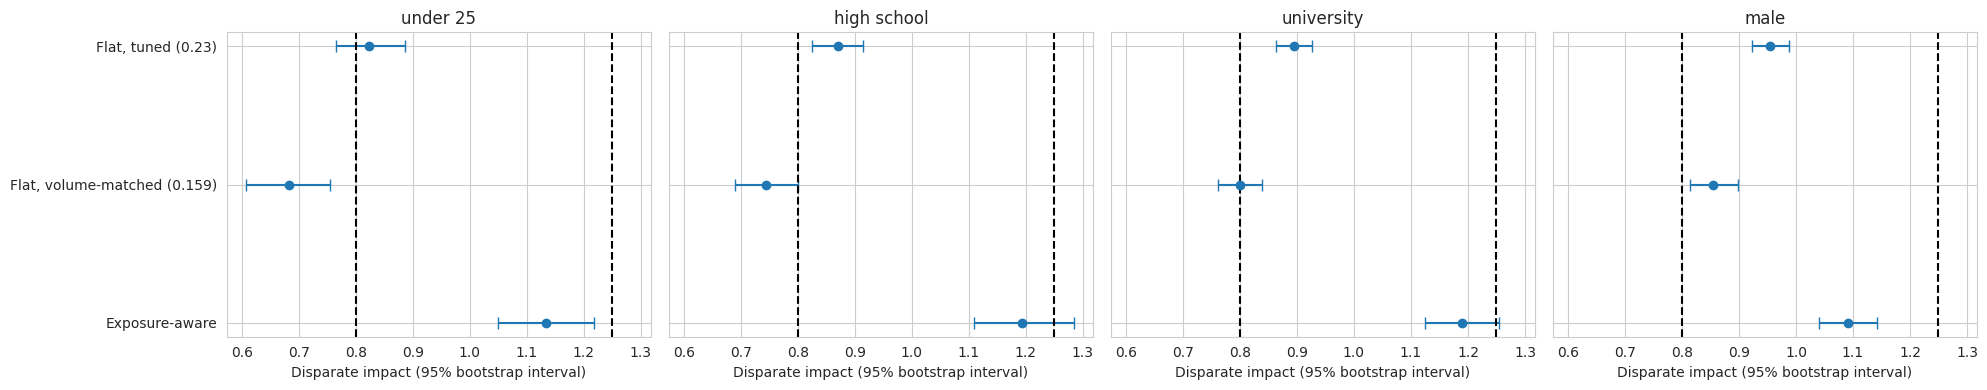

In [63]:
def fit_reference(frame, ccf, floor_q=0.05):
    exposure, revenue_base = raw_economics(frame, ccf)
    floor = np.quantile(revenue_base[revenue_base > 0], floor_q)
    return {
        "floor": floor,
        "exposure_median": np.median(exposure),
        "margin_median": np.median(np.maximum(revenue_base, floor)),
    }


def run_scenario(ccf, ratio, floor_q=0.05):
    reference = fit_reference(X_train, ccf, floor_q)
    margin_train, loss_train = customer_economics(X_train, ccf, ratio, reference)
    margin_eval, loss_eval = customer_economics(X_test, ccf, ratio, reference)
    flat_cutoff = tuned_flat_cutoff(oof_prob, train_actual, margin_train, loss_train)
    customer_cutoff = margin_eval / (margin_eval + loss_eval)
    return {
        "margin": margin_eval,
        "loss": loss_eval,
        "flat_cutoff": flat_cutoff,
        "customer_cutoff": customer_cutoff,
        "flat_approved": test_prob < flat_cutoff,
        "exposure_approved": test_prob < customer_cutoff,
    }


floor_rows = []
for floor_q in [0.05, 0.10, 0.25, 0.50]:
    s = run_scenario(BASE_CCF, BASE_RATIO, floor_q)
    flat_profit = realized_profit(s["flat_approved"], test_actual, s["margin"], s["loss"])
    exposure_profit = realized_profit(s["exposure_approved"], test_actual, s["margin"], s["loss"])
    delta = (exposure_profit[boot_idx] - flat_profit[boot_idx]).sum(axis=1) / len(test_actual) * 1000
    low, high = np.quantile(delta, [0.025, 0.975])
    floor_rows.append({
        "floor_quantile": floor_q,
        "flat_cutoff": s["flat_cutoff"],
        "flat_approval": s["flat_approved"].mean(),
        "exposure_approval": s["exposure_approved"].mean(),
        "uplift_per_1000": (exposure_profit.mean() - flat_profit.mean()) * 1000,
        "ci_low": low,
        "ci_high": high,
        "excludes_zero": bool(low > 0 or high < 0),
        "share_cutoff_under_2pct": float((s["customer_cutoff"] < 0.02).mean()),
    })

floor_table = pd.DataFrame(floor_rows)
floor_table.round(4).to_csv("reports/expected_profit_floor_sensitivity.csv", index=False)
print("Margin-floor sensitivity (base case CCF 0.5, ratio 5)")
display(floor_table.round(3))

exposure_test, revenue_test = raw_economics(X_test, BASE_CCF)
segment = np.where(scenario["customer_cutoff"] < 0.02, "cutoff under 0.02", "cutoff 0.02 and above")
profile = (
    pd.DataFrame({
        "segment": segment,
        "limit": X_test["LIMIT_BAL"].to_numpy(),
        "avg_positive_bill": revenue_test,
        "exposure": exposure_test,
        "predicted_pd": test_prob,
        "default": test_actual,
        "approved": exposure_approved,
    })
    .groupby("segment")
    .agg(
        customers=("limit", "size"),
        median_limit=("limit", "median"),
        median_avg_bill=("avg_positive_bill", "median"),
        median_exposure=("exposure", "median"),
        mean_predicted_pd=("predicted_pd", "mean"),
        default_rate=("default", "mean"),
        approval_rate=("approved", "mean"),
    )
)
profile["share_of_applicants"] = profile["customers"] / len(test_actual)
profile.round(3).to_csv("reports/expected_profit_spike_profile.csv")
print("Profile of customers with near-zero cutoffs")
display(profile.round(3))

band_order = ["<50k", "50-100k", "100-200k", "200-400k", "400k+"]
band_table = band_table.loc[band_order]
band_table.round(3).to_csv("reports/expected_profit_limit_bands.csv")
print("Approval rate by credit limit band (ordered)")
display(band_table.round(3))

matched_cutoff = float(np.quantile(test_prob, exposure_approved.mean()))
comparison_policies = {
    f"Flat, tuned ({scenario['flat_cutoff']:.2f})": flat_approved,
    f"Flat, volume-matched ({matched_cutoff:.3f})": test_prob < matched_cutoff,
    "Exposure-aware": exposure_approved,
}
profit_by_policy = {
    name: realized_profit(approved, test_actual, margin_test, loss_test)
    for name, approved in comparison_policies.items()
}
names = list(comparison_policies)

control_table = pd.DataFrame([
    {
        "policy": name,
        "approval_rate": approved.mean(),
        "bad_rate_among_approved": test_actual[approved].mean(),
        "profit_per_1000": profit_by_policy[name].mean() * 1000,
    }
    for name, approved in comparison_policies.items()
])
print("Volume-matched control")
display(control_table.round(4))

matched_delta = (
    profit_by_policy[names[2]][boot_idx] - profit_by_policy[names[1]][boot_idx]
).sum(axis=1) / len(test_actual) * 1000
matched_low, matched_high = np.quantile(matched_delta, [0.025, 0.975])
matched_point = (profit_by_policy[names[2]].mean() - profit_by_policy[names[1]].mean()) * 1000
print(
    f"Exposure-aware minus volume-matched flat: {matched_point:.1f} per 1,000 "
    f"[{matched_low:.1f}, {matched_high:.1f}]"
)

GROUP_SPECS = [
    ("under 25", age_arr, "<25", "25-34"),
    ("high school", edu_arr, "High school", "Graduate school"),
    ("university", edu_arr, "University", "Graduate school"),
    ("male", sex_arr, "Male", "Female"),
]

di_rows = []
for name, approved in comparison_policies.items():
    for label, groups, target, reference_group in GROUP_SPECS:
        values = np.empty(len(boot_idx))
        for k, idx in enumerate(boot_idx):
            g, a = groups[idx], approved[idx]
            values[k] = a[g == target].mean() / a[g == reference_group].mean()
        point = approved[groups == target].mean() / approved[groups == reference_group].mean()
        low, high = np.quantile(values, [0.025, 0.975])
        di_rows.append({
            "policy": name,
            "group": label,
            "estimate": point,
            "ci_low": low,
            "ci_high": high,
            "share_below_0.80": float((values < 0.8).mean()),
            "share_above_1.25": float((values > 1.25).mean()),
        })

di_summary = pd.DataFrame(di_rows)
di_summary.round(4).to_csv("reports/expected_profit_fairness_bootstrap.csv", index=False)
di_summary["reported"] = di_summary.apply(
    lambda r: f"{r['estimate']:.3f} [{r['ci_low']:.3f}, {r['ci_high']:.3f}]", axis=1
)
print("Disparate impact, estimate [95% interval]")
display(di_summary.pivot(index="group", columns="policy", values="reported")[names])
print("Share of replicates outside the 0.80 to 1.25 band")
outside = di_summary.assign(outside=di_summary["share_below_0.80"] + di_summary["share_above_1.25"])
display(outside.pivot(index="group", columns="policy", values="outside")[names].round(3))

fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharex=True)
positions = np.arange(len(names))
for ax, (label, _, _, _) in zip(axes, GROUP_SPECS):
    part = di_summary[di_summary["group"] == label].set_index("policy").loc[names]
    ax.errorbar(
        part["estimate"], positions,
        xerr=[part["estimate"] - part["ci_low"], part["ci_high"] - part["estimate"]],
        fmt="o", capsize=4,
    )
    ax.axvline(0.8, ls="--", c="k")
    ax.axvline(1.25, ls="--", c="k")
    ax.set_yticks(positions)
    ax.set_yticklabels(names if label == GROUP_SPECS[0][0] else [""] * len(names))
    ax.invert_yaxis()
    ax.set_title(label)
    ax.set_xlabel("Disparate impact (95% bootstrap interval)")
plt.tight_layout()
plt.savefig("reports/figures/expected_profit_fairness_ci.png", dpi=150)
plt.show()

PACKAGING

In [64]:
%%writefile .gitignore
data/*
!data/.gitkeep
models/
__pycache__/
.ipynb_checkpoints/

Overwriting .gitignore


In [66]:
from data import download_raw, standardize, validate

check = validate(standardize(download_raw()))
print(check.shape, round(check["DEFAULT_FLAG"].mean(), 4))

(30000, 25) 0.2212


In [69]:
!touch data/.gitkeep

In [71]:
!zip -qr /content/project_backup.zip /content/credit-default-risk -x "*/.git/*"

In [72]:
%cd /content/credit-default-risk
!ls
!ls notebooks
!head -3 README.md
!head -3 reports/findings_log.md

/content/credit-default-risk
data  models  notebooks  README.md  reports  requirements.txt  sql  src
**Credit Card Default Risk: From SQL Analysis to Auditable Approval Decisions**

**About the data**
 Findings log (final figures)

SQL and statistical tests


In [74]:
!git config user.name "Harsh Pratap"
!git config user.email "harshprataps2703@gmail.com"
!git config user.name
!git config user.email
!git status --short

Harsh Pratap
harshprataps2703@gmail.com
A  .gitignore
A  README.md
A  data/.gitkeep
A  reports/bootstrap_four_fifths_probability.csv
A  reports/bootstrap_paired_differences.csv
A  reports/bootstrap_summary.csv
A  reports/cost_sensitivity.csv
A  reports/cutoff_table.csv
A  reports/cv_results.csv
A  reports/decile_lift.csv
A  reports/demographics_ablation_fairness.csv
A  reports/demographics_ablation_performance.csv
A  reports/expected_profit_disparate_impact.csv
A  reports/expected_profit_fairness_bootstrap.csv
A  reports/expected_profit_floor_sensitivity.csv
A  reports/expected_profit_limit_bands.csv
A  reports/expected_profit_policies.csv
A  reports/expected_profit_robustness.csv
A  reports/expected_profit_spike_profile.csv
A  reports/fairness_audit.csv
A  reports/figures/approval_vs_badrate.png
A  reports/figures/bootstrap_fairness_ci.png
A  reports/figures/cost_sensitivity.png
A  reports/figures/decile_lift.png
A  reports/figures/demographics_ablation.png
A  reports/figures/eda_over

In [75]:
%cd /content/credit-default-risk
!ls -la notebooks

/content/credit-default-risk
total 8
drwxr-xr-x 2 root root 4096 Nov  2 04:12 .
drwxr-xr-x 9 root root 4096 Nov  2 04:44 ..
